# Formula 1 Podium Prediction — Milestone 1

**Prediction:** Will a driver who starts a Grand Prix finish in the top three?
The cutoff is after qualifying and before the main race. The notebook is a
complete, top-to-bottom audit, analysis, modeling experiment, and inference
demonstration. The linked Kaggle dataset is the 1950–2024 Ergast snapshot.
All figures and machine-readable results are written to `outputs/`.

Sections: setup → raw EDA → cleaning → post-cleaning EDA → three engineering
questions → leakage-safe features → selection and split → preprocessing-order
experiments → four model families → ablation → SHAP, permutation and LIME →
inference → limitations. Every model uses the same starter rows and columns.

## 1. Setup and reproducibility
Attach the public Kaggle dataset **Formula 1 World Championship (1950–2024)**
to this notebook. A local run accepts `data/raw/` or `F1_DATA_DIR`. Kaggle
Internet must be on if the optional explanation packages need installation.

In [1]:
import importlib.util
import os
import re
import subprocess
import sys
from pathlib import Path
from collections import Counter

for module, package in [("shap", "shap"), ("lime", "lime==0.2.0.1")]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", package, "-q"])

import numpy as np
import pandas as pd
import matplotlib
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from statsmodels.formula.api import glm
from statsmodels.genmod.families import Binomial
from statsmodels.stats.proportion import proportion_confint
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score,
                             precision_score, recall_score, precision_recall_curve,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
from sklearn.exceptions import ConvergenceWarning
import json
import warnings
from IPython.display import display, Markdown

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", message="IProgress not found.*")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (10, 5), "figure.dpi": 110})
ROOT = Path.cwd()
OUT = ROOT / "outputs"
FIG = OUT / "figures"
TABLE = OUT / "tables"
for directory in (FIG, TABLE):
    directory.mkdir(parents=True, exist_ok=True)
SUMMARY = {"dataset": {}, "cleaning": {}, "questions": {}, "modeling": {}, "xai": {}}

def save_plot(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=170, bbox_inches="tight")
    if "ipykernel" in sys.modules:
        plt.show()
    plt.close()

def save_table(name, frame):
    frame.to_csv(TABLE / f"{name}.csv", index=False)
    return frame

def find_data_dir():
    required = {f"{x}.csv" for x in ["circuits", "constructors", "constructor_results",
        "constructor_standings", "drivers", "driver_standings", "races", "results",
        "qualifying", "lap_times", "pit_stops", "sprint_results", "seasons", "status"]}
    candidates = []
    if os.environ.get("F1_DATA_DIR"):
        candidates.append(Path(os.environ["F1_DATA_DIR"]))
    candidates.extend([ROOT / "data" / "raw", Path.home() / "OneDrive" / "Desktop" / "ML Dataset" / "data"])
    candidates.extend(Path("/kaggle/input").glob("**/results.csv"))
    for candidate in candidates:
        folder = candidate.parent if candidate.is_file() else candidate
        if folder.is_dir() and required.issubset({p.name for p in folder.iterdir()}):
            return folder
    raise FileNotFoundError("Attach the 14-table Kaggle F1 dataset or set F1_DATA_DIR to its CSV folder.")

DATA_DIR = find_data_dir()
TABLES = ["circuits", "constructors", "constructor_results", "constructor_standings",
          "drivers", "driver_standings", "races", "results", "qualifying", "lap_times",
          "pit_stops", "sprint_results", "seasons", "status"]
print("Dataset folder:", DATA_DIR.name, "| output folder:", OUT.name)

Dataset folder: data | output folder: outputs


## 2. Raw-table EDA and integrity audit
Read every CSV as text first: this preserves literal `\\N` and avoids hiding
sentinel and type problems. No raw frame is mutated below.

                table   rows  columns  sentinels
            lap_times 589081        6          0
     driver_standings  34863        7          0
              results  26759       18     122887
constructor_standings  13391        7          0
  constructor_results  12625        5      12608
            pit_stops  11371        7          0
           qualifying  10494        9      11668
                races   1125       18      11349
              drivers    861        9       1559
       sprint_results    360       16         73
         constructors    212        5          0
               status    139        2          0
             circuits     77        9          0
              seasons     75        2          0


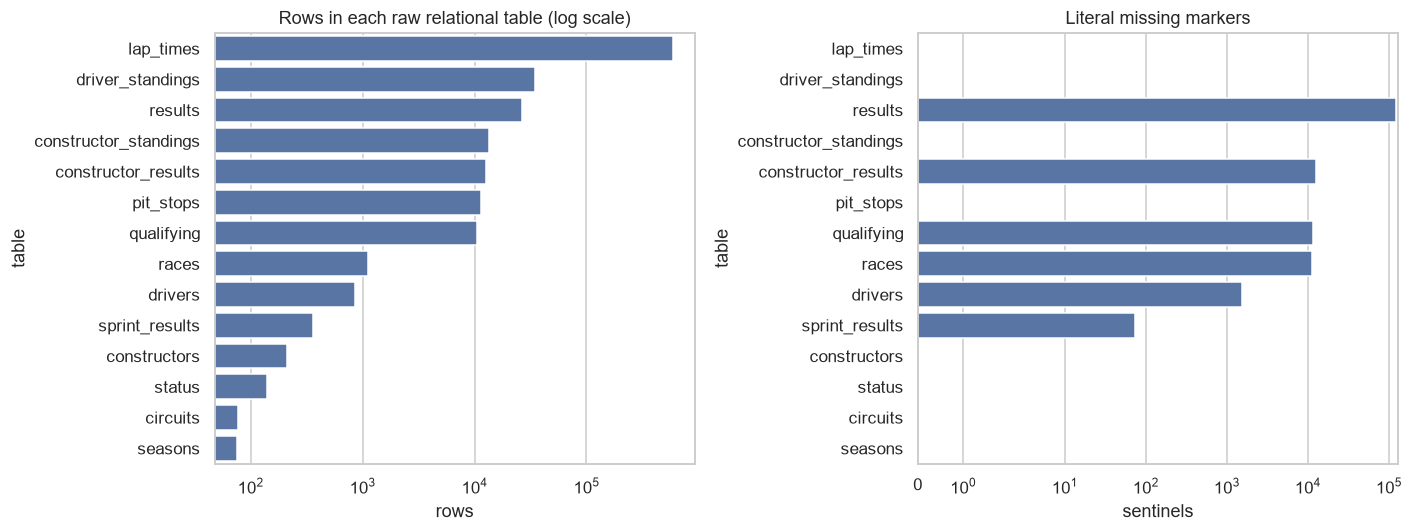

Most affected columns:
               table       column  missing  percent
constructor_results       status    12608    99.87
              races  sprint_time     1110    98.67
              races  sprint_date     1107    98.40
              races     fp3_time     1072    95.29
              races     fp1_time     1057    93.96
              races   quali_time     1057    93.96
              races     fp2_time     1057    93.96
              races     fp3_date     1053    93.60
            drivers       number      802    93.15
              races   quali_date     1035    92.00
              races     fp2_date     1035    92.00
              races     fp1_date     1035    92.00
            drivers         code      757    87.92
            results         time    19079    71.30
            results milliseconds    19079    71.30


In [2]:
raw = {name: pd.read_csv(DATA_DIR / f"{name}.csv", dtype=str, keep_default_na=False)
       for name in TABLES}
overview = pd.DataFrame([{"table": name, "rows": len(df), "columns": len(df.columns),
                          "sentinels": int(df.isin([r"\N", ""]).sum().sum())}
                         for name, df in raw.items()]).sort_values("rows", ascending=False)
save_table("raw_overview", overview)
print(overview.to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=overview, y="table", x="rows", ax=axes[0]); axes[0].set_xscale("log")
axes[0].set_title("Rows in each raw relational table (log scale)")
sns.barplot(data=overview, y="table", x="sentinels", ax=axes[1])
axes[1].set_xscale("symlog"); axes[1].set_title("Literal missing markers")
save_plot("01_raw_overview")

raw_missing = pd.DataFrame([
    {"table": table, "column": col, "missing": int(df[col].isin([r"\N", ""]).sum()),
     "percent": round(100 * df[col].isin([r"\N", ""]).mean(), 2)}
    for table, df in raw.items() for col in df.columns
]).sort_values("percent", ascending=False)
save_table("raw_missingness", raw_missing)
print("Most affected columns:\n", raw_missing.head(15).to_string(index=False))

In [3]:
numeric_cols = {
    "circuits": "circuitId lat lng alt", "constructors": "constructorId",
    "constructor_results": "constructorResultsId raceId constructorId points",
    "constructor_standings": "constructorStandingsId raceId constructorId points position wins",
    "drivers": "driverId number", "driver_standings": "driverStandingsId raceId driverId points position wins",
    "races": "raceId year round circuitId",
    "results": "resultId raceId driverId constructorId number grid position positionOrder points laps milliseconds fastestLap rank fastestLapSpeed statusId",
    "qualifying": "qualifyId raceId driverId constructorId number position",
    "lap_times": "raceId driverId lap position milliseconds",
    "pit_stops": "raceId driverId stop lap milliseconds",
    "sprint_results": "resultId raceId driverId constructorId number grid position positionOrder points laps milliseconds fastestLap statusId",
    "seasons": "year", "status": "statusId",
}
date_cols = {"races": ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"],
             "drivers": ["dob"]}
duration_cols = {"qualifying": ["q1", "q2", "q3"], "results": ["fastestLapTime"],
                 "sprint_results": ["fastestLapTime"], "lap_times": ["time"],
                 "pit_stops": ["duration"]}

def duration_seconds(value):
    if pd.isna(value):
        return np.nan
    try:
        n = 0.0
        for part in str(value).split(":"):
            n = n * 60 + float(part)
        return n
    except ValueError:
        return np.nan

assert duration_seconds("1:23.456") == 83.456
assert duration_seconds("16:44.718") == 1004.718
clean = {name: df.replace({r"\N": np.nan, "": np.nan}).copy() for name, df in raw.items()}
typing_rows = []
for name, df in clean.items():
    for col in numeric_cols[name].split():
        if col in df:
            before = df[col].notna().sum()
            df[col] = pd.to_numeric(df[col], errors="coerce")
            typing_rows.append({"field": f"{name}.{col}", "parse_failures": int(before-df[col].notna().sum())})
    for col in date_cols.get(name, []):
        before = df[col].notna().sum()
        df[col] = pd.to_datetime(df[col], errors="coerce")
        typing_rows.append({"field": f"{name}.{col}", "parse_failures": int(before-df[col].notna().sum())})
    for col in duration_cols.get(name, []):
        before = df[col].notna().sum()
        df[f"{col}_seconds"] = df[col].map(duration_seconds)
        typing_rows.append({"field": f"{name}.{col}",
                            "parse_failures": int(before-df[f"{col}_seconds"].notna().sum())})
typing_report = save_table("semantic_typing", pd.DataFrame(typing_rows))
print("Unexpected parse failures:\n", typing_report.query("parse_failures > 0").to_string(index=False))
assert sum((df == r"\N").sum().sum() for df in clean.values()) == 0

Unexpected parse failures:
 Empty DataFrame
Columns: [field, parse_failures]
Index: []


Physical primary keys must be unique and non-null. `results` has a separate
*logical* driver-race grain which can duplicate in 1950s shared drives; that
logical issue is fixed below. Null foreign keys and orphan references are
shown separately so a genuinely optional reference is not called an orphan.

In [4]:
primary_keys = {"circuits": ["circuitId"], "constructors": ["constructorId"],
    "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"], "drivers": ["driverId"],
    "driver_standings": ["driverStandingsId"], "races": ["raceId"],
    "results": ["resultId"], "qualifying": ["qualifyId"],
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"],
    "sprint_results": ["resultId"], "seasons": ["year"], "status": ["statusId"]}
pk_audit = save_table("primary_keys", pd.DataFrame([
    {"table": name, "key": "+".join(cols), "null_keys": int(df[cols].isna().any(axis=1).sum()),
     "duplicate_keys": int(df.duplicated(cols).sum())}
    for name, df in clean.items() for cols in [primary_keys[name]]]))
print(pk_audit.to_string(index=False))
assert pk_audit[["null_keys", "duplicate_keys"]].sum().sum() == 0

foreign_keys = [("results", "raceId", "races", "raceId"),
 ("results", "driverId", "drivers", "driverId"), ("results", "constructorId", "constructors", "constructorId"),
 ("results", "statusId", "status", "statusId"), ("races", "circuitId", "circuits", "circuitId"),
 ("races", "year", "seasons", "year"), ("qualifying", "raceId", "races", "raceId"),
 ("qualifying", "driverId", "drivers", "driverId"), ("qualifying", "constructorId", "constructors", "constructorId"),
 ("driver_standings", "raceId", "races", "raceId"), ("driver_standings", "driverId", "drivers", "driverId"),
 ("constructor_standings", "raceId", "races", "raceId"),
 ("constructor_standings", "constructorId", "constructors", "constructorId"),
 ("constructor_results", "raceId", "races", "raceId"),
 ("constructor_results", "constructorId", "constructors", "constructorId"),
 ("sprint_results", "raceId", "races", "raceId"), ("sprint_results", "driverId", "drivers", "driverId"),
 ("sprint_results", "constructorId", "constructors", "constructorId"),
 ("sprint_results", "statusId", "status", "statusId"),
 ("lap_times", "raceId", "races", "raceId"), ("lap_times", "driverId", "drivers", "driverId"),
 ("pit_stops", "raceId", "races", "raceId"), ("pit_stops", "driverId", "drivers", "driverId")]
fk_audit = save_table("foreign_keys", pd.DataFrame([
    {"relation": f"{child}.{col} -> {parent}.{parent_col}",
     "null_references": int(clean[child][col].isna().sum()),
     "orphan_references": int((~clean[child][col].dropna().isin(clean[parent][parent_col])).sum())}
    for child, col, parent, parent_col in foreign_keys]))
print(fk_audit.to_string(index=False))
assert fk_audit.orphan_references.sum() == 0

                table                    key  null_keys  duplicate_keys
             circuits              circuitId          0               0
         constructors          constructorId          0               0
  constructor_results   constructorResultsId          0               0
constructor_standings constructorStandingsId          0               0
              drivers               driverId          0               0
     driver_standings      driverStandingsId          0               0
                races                 raceId          0               0
              results               resultId          0               0
           qualifying              qualifyId          0               0
            lap_times    raceId+driverId+lap          0               0
            pit_stops   raceId+driverId+stop          0               0
       sprint_results               resultId          0               0
              seasons                   year          0         

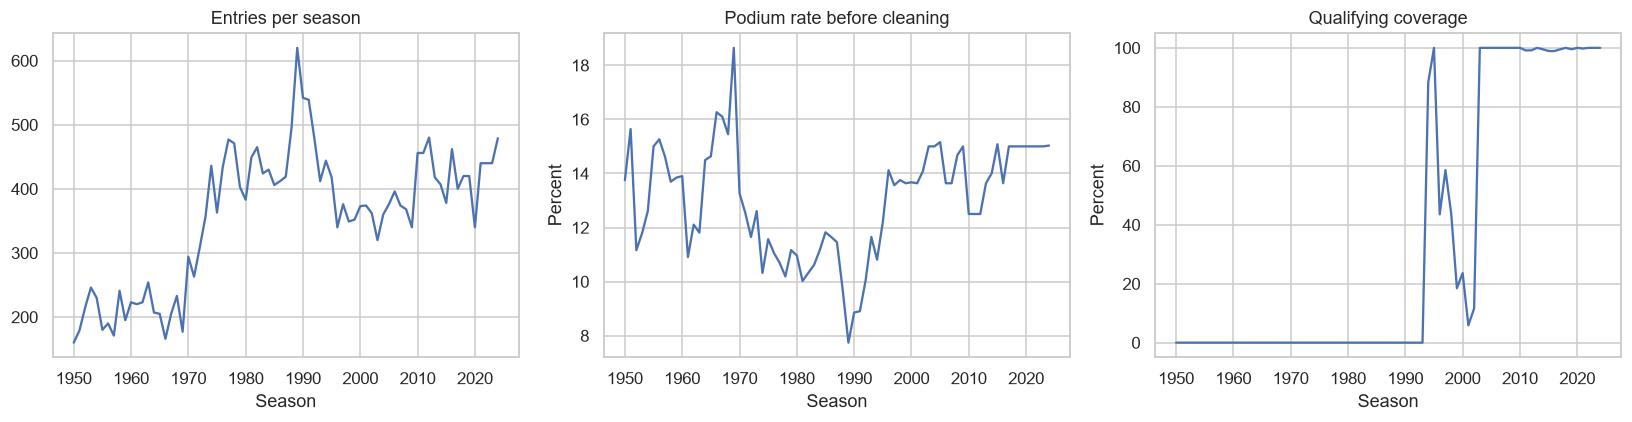

Qualifying coverage, 1993–2004:
  year  qualifying_coverage
 1993             0.000000
 1994             0.882883
 1995             1.000000
 1996             0.435294
 1997             0.585106
 1998             0.438395
 1999             0.184659
 2000             0.235925
 2001             0.058824
 2002             0.116022
 2003             1.000000
 2004             1.000000


In [5]:
race_info = clean["races"][["raceId", "year", "round", "date", "name", "circuitId"]]
pre_eda = clean["results"].merge(race_info, on="raceId", validate="many_to_one")
pre_eda["podium"] = (pre_eda.positionOrder <= 3).astype(int)
pre_eda["has_qualifying"] = pre_eda.set_index(["raceId", "driverId"]).index.isin(
    clean["qualifying"].set_index(["raceId", "driverId"]).index)
pre_by_year = pre_eda.groupby("year").agg(rows=("driverId", "size"), podium_rate=("podium", "mean"),
                                          qualifying_coverage=("has_qualifying", "mean")).reset_index()
save_table("raw_by_year", pre_by_year)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(pre_by_year.year, pre_by_year.rows); axes[0].set_title("Entries per season")
axes[1].plot(pre_by_year.year, 100*pre_by_year.podium_rate); axes[1].set_title("Podium rate before cleaning")
axes[2].plot(pre_by_year.year, 100*pre_by_year.qualifying_coverage); axes[2].set_title("Qualifying coverage")
for ax in axes: ax.set_xlabel("Season")
axes[1].set_ylabel("Percent"); axes[2].set_ylabel("Percent")
save_plot("02_raw_era_eda")
print("Qualifying coverage, 1993–2004:\n", pre_by_year.query("1993 <= year <= 2004")[
    ["year", "qualifying_coverage"]].to_string(index=False))
SUMMARY["dataset"].update({"raw_results": int(len(pre_eda)), "years": [int(pre_by_year.year.min()), int(pre_by_year.year.max())],
                           "qualifying_2002": float(pre_by_year.loc[pre_by_year.year==2002,"qualifying_coverage"].iloc[0]),
                           "qualifying_2003": float(pre_by_year.loc[pre_by_year.year==2003,"qualifying_coverage"].iloc[0])})

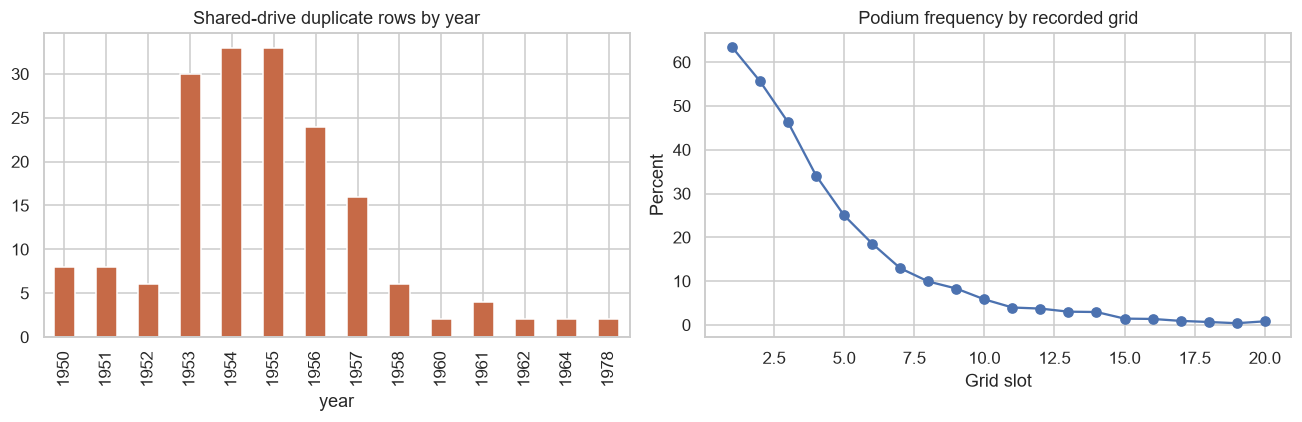

Duplicate pairs: 85 | excess rows: 91
Grid zero rows: 1638 | F/W results: 1704


In [6]:
dup_raw = pre_eda.loc[pre_eda.duplicated(["raceId", "driverId"], keep=False)]
dup_year = dup_raw.groupby("year").size()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
dup_year.plot.bar(ax=axes[0], color="#c66a47"); axes[0].set_title("Shared-drive duplicate rows by year")
grid_eda = pre_eda.loc[pre_eda.grid.between(1, 20)].groupby("grid").podium.agg(["mean", "size"])
axes[1].plot(grid_eda.index, 100*grid_eda["mean"], marker="o")
axes[1].set_title("Podium frequency by recorded grid"); axes[1].set_xlabel("Grid slot"); axes[1].set_ylabel("Percent")
save_plot("03_duplicates_and_grid")
print("Duplicate pairs:", dup_raw[["raceId", "driverId"]].drop_duplicates().shape[0],
      "| excess rows:", pre_eda.duplicated(["raceId", "driverId"]).sum())
print("Grid zero rows:", int((pre_eda.grid==0).sum()), "| F/W results:", int(pre_eda.positionText.isin(["F","W"]).sum()))

## 3. Cleaning decisions and post-cleaning EDA
`grid=0` is a pit-lane start if laps were completed; it is not pole. Exclude
non-starters signaled by F/W, known non-start statuses, or grid zero with zero
laps. The Indianapolis 500 was part of the 1950–1960 championship but a
different field and race format; its 11 races are excluded from analysis and
modeling, with the impact measured here. For shared drives, keep the row for
the unique positive-grid car the driver started, else the best finish, then
smallest `resultId` as a deterministic tie-break. This preserves the
driver-race label while prioritizing information known at prediction time.

Historical races with more than three credited podium drivers: 7
                    step  rows  removed
             Raw results 26759        0
Exclude Indianapolis 500 26354      405
    Exclude non-starters 24615     1739
   Resolve shared drives 24551       64


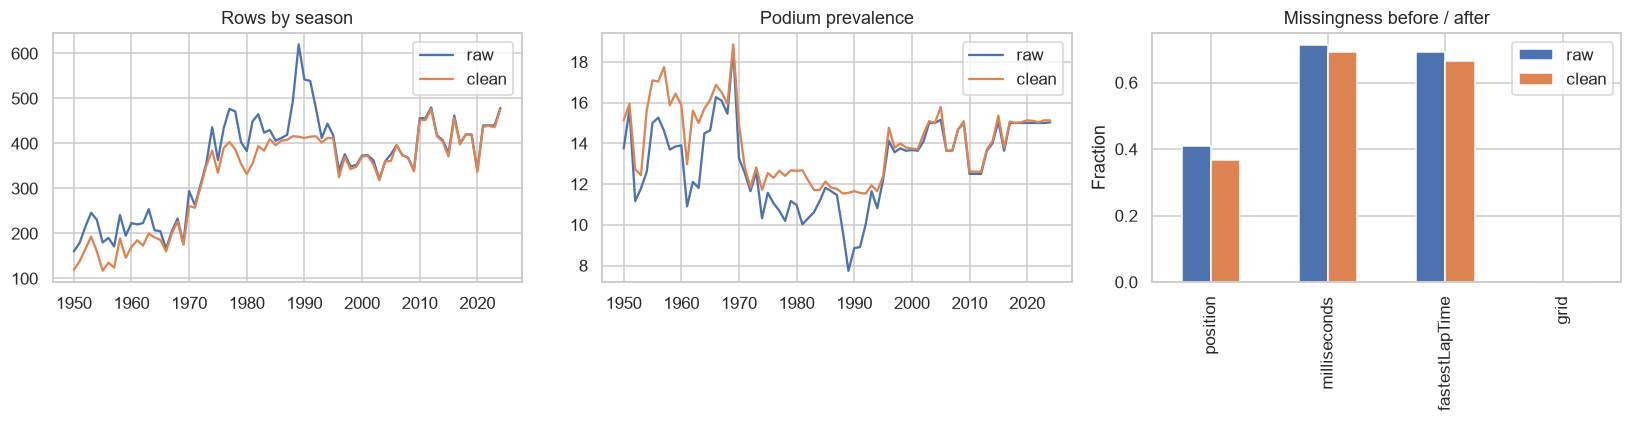

Grain duplicates before: 91 after: 0


In [7]:
indy_ids = set(clean["races"].loc[clean["races"].name.str.contains("Indianapolis 500", case=False, na=False), "raceId"])
status_lookup = clean["status"].set_index("statusId").status
work = clean["results"].copy()
work["status_text"] = work.statusId.map(status_lookup)
work["nonstarter"] = (work.positionText.isin(["F", "W"]) |
    work.status_text.isin(["Did not qualify", "Did not prequalify", "Withdrew", "107% Rule"]) |
    ((work.grid == 0) & (work.laps == 0)))
removed_indy = int(work.raceId.isin(indy_ids).sum())
work = work.loc[~work.raceId.isin(indy_ids)].copy()
removed_nonstarters = int(work.nonstarter.sum())
work = work.loc[~work.nonstarter].copy()
work["slot_occupants"] = work.groupby(["raceId", "grid"])["driverId"].transform("nunique")
work["unique_started_car"] = (work.grid > 0) & (work.slot_occupants == 1)
before_dedup = len(work)
work = work.sort_values(["raceId", "driverId", "unique_started_car", "positionOrder", "resultId"],
                        ascending=[True, True, False, True, True])
starts = work.drop_duplicates(["raceId", "driverId"]).drop(
    columns=["status_text", "nonstarter", "slot_occupants", "unique_started_car"])
starts = starts.merge(race_info, on="raceId", validate="many_to_one")
starts["podium"] = (starts.positionOrder <= 3).astype(int)
starts = starts.sort_values(["year", "round", "raceId", "driverId"]).reset_index(drop=True)
assert not starts.duplicated(["raceId", "driverId"]).any()
assert not starts.positionText.isin(["F", "W"]).any()
historical_multi_podium_races=int((starts.groupby("raceId").podium.sum()>3).sum())
print("Historical races with more than three credited podium drivers:",historical_multi_podium_races)
cleaning_log = save_table("cleaning_log", pd.DataFrame([
    {"step": "Raw results", "rows": len(pre_eda), "removed": 0},
    {"step": "Exclude Indianapolis 500", "rows": len(pre_eda)-removed_indy, "removed": removed_indy},
    {"step": "Exclude non-starters", "rows": before_dedup, "removed": removed_nonstarters},
    {"step": "Resolve shared drives", "rows": len(starts), "removed": before_dedup-len(starts)},
]))
print(cleaning_log.to_string(index=False))
SUMMARY["cleaning"].update({"starts": int(len(starts)), "indy_removed": removed_indy,
    "nonstarters_removed": removed_nonstarters, "duplicates_removed": before_dedup-len(starts),
    "podium_rate": float(starts.podium.mean()),
    "historical_multi_podium_races":historical_multi_podium_races})

post_by_year = starts.groupby("year").agg(rows=("driverId", "size"), podium_rate=("podium", "mean")).reset_index()
save_table("clean_by_year", post_by_year)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(pre_by_year.year, pre_by_year.rows, label="raw")
axes[0].plot(post_by_year.year, post_by_year.rows, label="clean"); axes[0].legend(); axes[0].set_title("Rows by season")
axes[1].plot(pre_by_year.year, 100*pre_by_year.podium_rate, label="raw")
axes[1].plot(post_by_year.year, 100*post_by_year.podium_rate, label="clean")
axes[1].legend(); axes[1].set_title("Podium prevalence")
before_missing = pre_eda[["position", "milliseconds", "fastestLapTime", "grid"]].isna().mean()
after_missing = starts[["position", "milliseconds", "fastestLapTime", "grid"]].isna().mean()
pd.DataFrame({"raw": before_missing, "clean": after_missing}).plot.bar(ax=axes[2])
axes[2].set_title("Missingness before / after"); axes[2].set_ylabel("Fraction")
save_plot("04_cleaning_impact")
print("Grain duplicates before:", pre_eda.duplicated(["raceId","driverId"]).sum(),
      "after:", starts.duplicated(["raceId","driverId"]).sum())

## 4. Data-engineering question 1: front-row conversion
A front-row **start** means recorded grid 1 or 2. Qualifying position is a
separate pre-race measure and can differ after a penalty. The primary rates
cover all available years and count each starter once. Era rankings require
at least ten front-row starts before 2022, or four in the shorter 2022-2024
window; Wilson intervals display how uncertain small samples are. Circuit
layouts can change under one circuitId.

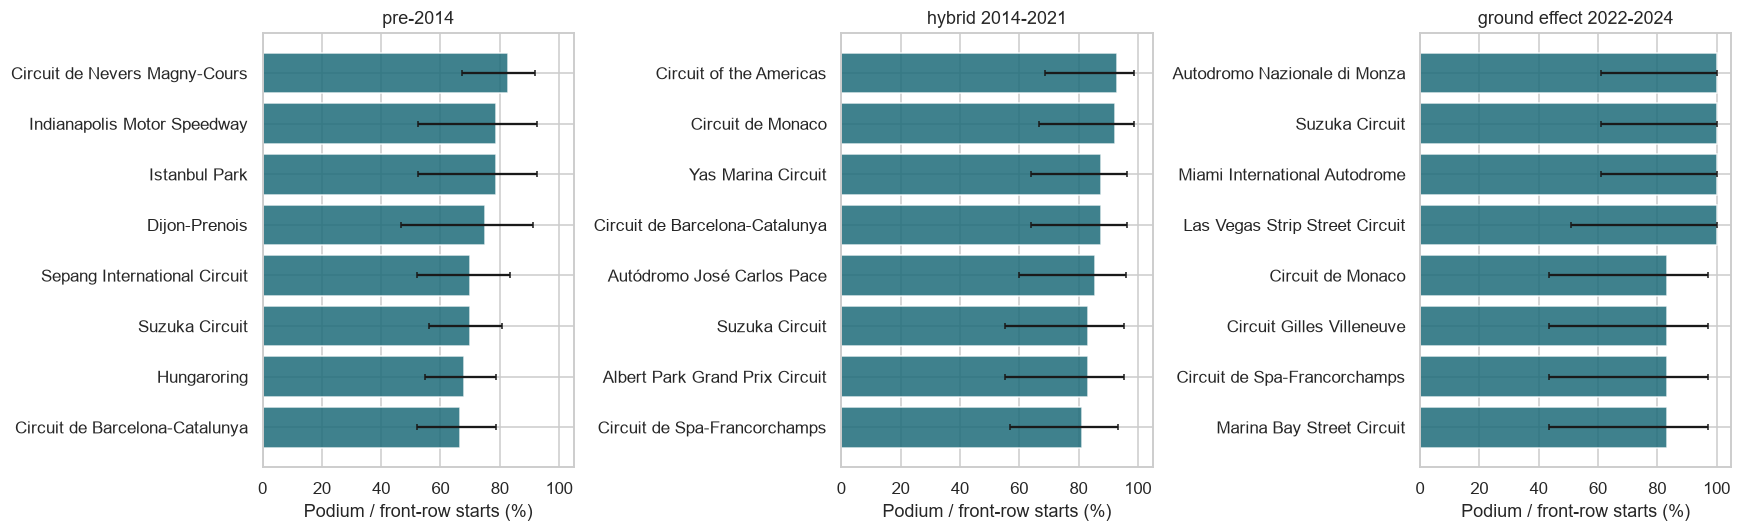

Front-row ranking change:
         period_a                period_b  shared_circuits  spearman_rho
        pre-2014        hybrid 2014-2021               16     -0.044511
hybrid 2014-2021 ground effect 2022-2024               17     -0.198836
        pre-2014 ground effect 2022-2024               17     -0.236781
Qualifying/grid distinction:
                     era  qualified_rows  qualifying_front_row  grid_front_row  changed_start
ground effect 2022-2024            1351                   135             135            401
       hybrid 2014-2021            3229                   318             318           1041
               pre-2014            5831                   530             530           1039


**Answer Q1.** Highest eligible conversion rates: pre-2014: **Circuit de Nevers Magny-Cours**, 82.9% (35 starts); hybrid 2014-2021: **Circuit of the Americas**, 92.9% (14 starts); ground effect 2022-2024: **Autodromo Nazionale di Monza**, 100.0% (6 starts). Ranking agreement across circuits active in both eras is shown by the Spearman table above; the short 2022–2024 window has wide uncertainty. Qualifying position and actual grid are separate columns; the grid-based answer covers the full history, while qualifying comparisons use only rows with a qualifying record. These are outcome rates, not pre-race features.

In [8]:
era_order = ["pre-2014", "hybrid 2014-2021", "ground effect 2022-2024"]
def era_of(year):
    return "pre-2014" if year < 2014 else ("hybrid 2014-2021" if year <= 2021 else "ground effect 2022-2024")

q1 = starts.merge(clean["circuits"][["circuitId", "name"]].rename(columns={"name":"circuit"}),
                  on="circuitId", validate="many_to_one")
q1["era"] = q1.year.map(era_of)
q1["grid_front_row"] = q1.grid.isin([1, 2])
q1 = q1.merge(clean["qualifying"][["raceId", "driverId", "position"]].rename(
    columns={"position":"qual_position"}), on=["raceId", "driverId"], how="left", validate="one_to_one")
q1["qual_front_row"] = q1.qual_position.isin([1, 2])
front = q1.loc[q1.grid_front_row].groupby(["era", "circuitId", "circuit"]).podium.agg(
    podiums="sum", starts="size").reset_index()
front["rate"] = front.podiums/front.starts
front[["low", "high"]] = np.array([proportion_confint(k, n, method="wilson")
                                     for k, n in zip(front.podiums, front.starts)])
min_starts_by_era={"pre-2014":10,"hybrid 2014-2021":10,"ground effect 2022-2024":4}
front["eligible_rank"] = front.apply(lambda r:r.starts>=min_starts_by_era[r.era],axis=1)
front["rank"] = front.loc[front.eligible_rank].groupby("era").rate.rank(ascending=False, method="min")
save_table("q1_front_row_conversion", front.sort_values(["era", "rate"], ascending=[True, False]))
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, era in zip(axes, era_order):
    top = front.loc[(front.era == era) & front.eligible_rank].nlargest(8, ["rate", "starts"]).sort_values("rate")
    ax.barh(top.circuit, 100*top.rate, xerr=[100*(top.rate-top.low),100*(top.high-top.rate)],
            color="#1d6b79", alpha=.85, capsize=2)
    ax.set_xlim(0, 105); ax.set_xlabel("Podium / front-row starts (%)"); ax.set_title(era)
save_plot("05_q1_front_row_by_era")

shared_rankings = []
for era_a, era_b in [(era_order[0], era_order[1]), (era_order[1], era_order[2]), (era_order[0], era_order[2])]:
    a = front.loc[(front.era==era_a) & front.eligible_rank, ["circuitId","rate"]].rename(columns={"rate":"a"})
    b = front.loc[(front.era==era_b) & front.eligible_rank, ["circuitId","rate"]].rename(columns={"rate":"b"})
    both = a.merge(b, on="circuitId")
    rho = spearmanr(both.a, both.b).statistic if len(both) >= 3 else np.nan
    shared_rankings.append({"period_a":era_a,"period_b":era_b,"shared_circuits":len(both),"spearman_rho":rho})
rank_compare = save_table("q1_rank_change", pd.DataFrame(shared_rankings))
qual_subset = q1.loc[q1.qual_position.notna()]
qual_grid = save_table("q1_qualifying_vs_grid", qual_subset.groupby("era").agg(
    qualified_rows=("driverId","size"), qualifying_front_row=("qual_front_row","sum"),
    grid_front_row=("grid_front_row","sum"),
    changed_start=("grid",lambda x: int((x.to_numpy()!=qual_subset.loc[x.index,"qual_position"].to_numpy()).sum()))
).reset_index())
print("Front-row ranking change:\n", rank_compare.to_string(index=False))
print("Qualifying/grid distinction:\n", qual_grid.to_string(index=False))
if "ipykernel" in sys.modules:
    snippets=[]
    for era in era_order:
        top=front.loc[(front.era==era)&front.eligible_rank].sort_values(["rate","starts"],ascending=False).iloc[0]
        snippets.append(f"{era}: **{top.circuit}**, {top.rate:.1%} ({int(top.starts)} starts)")
    display(Markdown("**Answer Q1.** Highest eligible conversion rates: "+"; ".join(snippets)+
        ". Ranking agreement across circuits active in both eras is shown by the Spearman table above; "
        "the short 2022–2024 window has wide uncertainty. Qualifying position and actual grid are "
        "separate columns; the grid-based answer covers the full history, while qualifying comparisons "
        "use only rows with a qualifying record. These are outcome rates, not pre-race features."))
SUMMARY["questions"]["q1"] = {
    "top_by_era": {era: front.loc[(front.era==era)&front.eligible_rank].sort_values(
        ["rate","starts"],ascending=False).head(3)[["circuit","rate","starts","low","high"]].to_dict("records")
        for era in era_order}, "rank_change": rank_compare.to_dict("records"),
    "qualifying_grid": qual_grid.to_dict("records")}

## 5. Data-engineering question 2: home race and grid position
`drivers.nationality` describes a person, while `circuits.country` describes
the location. Normalize explicit demonyms; leave mixed/unknown nationality
unclassified. Compare within grid buckets and fit a race-clustered logistic
model adjusted for both grid bucket and era. Its odds ratio is **association**,
not evidence that racing at home causes a podium.

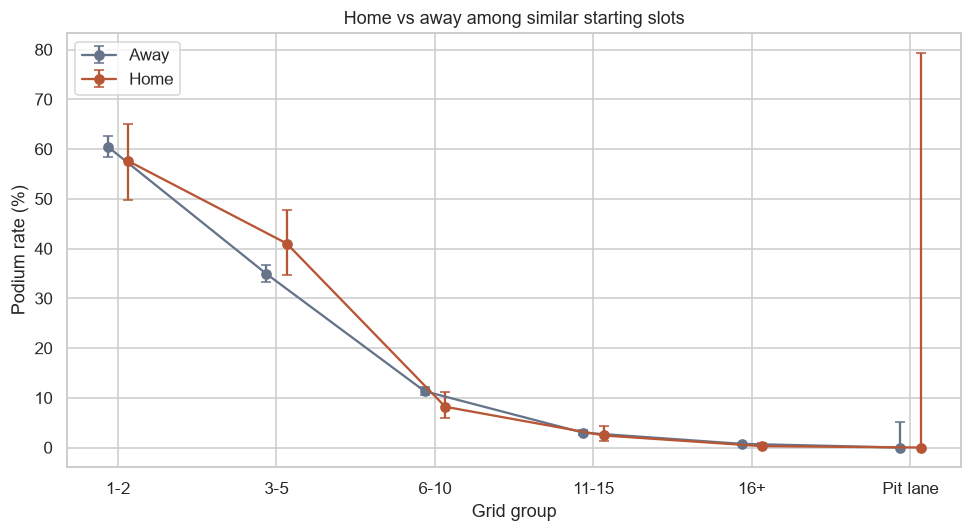

Adjusted home association: {'analyzed_starts': 24534, 'excluded_ambiguous_nationality': 17, 'home_starts': 1927, 'odds_ratio': 0.9340214833612365, 'or_low': 0.7902339847339674, 'or_high': 1.1039719225363573, 'adjusted_home_probability': 0.1312172532369112, 'adjusted_away_probability': 0.136862903811776}


**Answer Q2.** No clear adjusted home advantage is detected: home odds ratio **0.93** (race-clustered 95% CI 0.79–1.10). The comparison uses one actual start per driver-race, adjusts for grid bucket and era, excludes ambiguous nationalities, and is observational rather than causal.

In [9]:
nationality_country = {
 "American":"USA", "Argentine":"Argentina", "Argentinian":"Argentina",
 "Australian":"Australia", "Austrian":"Austria", "Belgian":"Belgium", "Brazilian":"Brazil",
 "British":"UK", "Canadian":"Canada", "Chinese":"China", "Dutch":"Netherlands",
 "East German":"Germany", "French":"France", "German":"Germany", "Hungarian":"Hungary",
 "Indian":"India", "Italian":"Italy", "Japanese":"Japan", "Malaysian":"Malaysia",
 "Mexican":"Mexico", "Monegasque":"Monaco", "Portuguese":"Portugal", "Russian":"Russia",
 "South African":"South Africa", "Spanish":"Spain", "Swedish":"Sweden", "Swiss":"Switzerland",
 "Thai":"Thailand", "Finnish":"Finland", "Danish":"Denmark", "Irish":"Ireland",
 "New Zealander":"New Zealand", "Polish":"Poland", "Czech":"Czechia", "Chilean":"Chile",
 "Colombian":"Colombia", "Indonesian":"Indonesia", "Liechtensteiner":"Liechtenstein",
 "Uruguayan":"Uruguay", "Venezuelan":"Venezuela"}
def canon_country(value):
    return {"United States":"USA", "UAE":"United Arab Emirates"}.get(value, value)
def grid_bucket(value):
    if value == 0: return "Pit lane"
    if value <= 2: return "1-2"
    if value <= 5: return "3-5"
    if value <= 10: return "6-10"
    if value <= 15: return "11-15"
    return "16+"

q2 = starts.merge(clean["drivers"][["driverId","nationality"]], on="driverId", validate="many_to_one")
q2 = q2.merge(clean["circuits"][["circuitId","country"]], on="circuitId", validate="many_to_one")
q2["driver_country"] = q2.nationality.str.strip().map(nationality_country)
q2["circuit_country"] = q2.country.map(canon_country)
q2["is_home"] = np.where(q2.driver_country.notna(), (q2.driver_country==q2.circuit_country).astype(int), np.nan)
q2["grid_bucket"] = q2.grid.map(grid_bucket)
q2["era"] = q2.year.map(era_of)
q2_valid = q2.loc[q2.is_home.notna()].copy()
home_by_grid = q2_valid.groupby(["grid_bucket","is_home"]).podium.agg(podiums="sum", starts="size").reset_index()
home_by_grid["rate"] = home_by_grid.podiums/home_by_grid.starts
home_by_grid[["low","high"]] = np.array([proportion_confint(k,n,method="wilson")
    for k,n in zip(home_by_grid.podiums,home_by_grid.starts)])
save_table("q2_home_by_grid", home_by_grid)
fig, ax = plt.subplots(figsize=(9,5))
bucket_order = ["1-2","3-5","6-10","11-15","16+","Pit lane"]
for home, label, color in [(0,"Away","#65748a"),(1,"Home","#b75534")]:
    part=home_by_grid.loc[home_by_grid.is_home==home].set_index("grid_bucket").reindex(bucket_order)
    x=np.arange(len(bucket_order))+(home-.5)*.13
    ax.errorbar(x, 100*part.rate, yerr=[100*(part.rate-part.low),100*(part.high-part.rate)],
                fmt="o-", capsize=3, label=label, color=color)
ax.set_xticks(range(len(bucket_order)),bucket_order); ax.set_xlabel("Grid group")
ax.set_ylabel("Podium rate (%)"); ax.set_title("Home vs away among similar starting slots"); ax.legend()
save_plot("06_q2_home_by_grid")
home_model = glm("podium ~ is_home + C(grid_bucket) + C(era)", data=q2_valid,
                 family=Binomial()).fit(cov_type="cluster",cov_kwds={"groups":q2_valid.raceId})
coef=float(home_model.params["is_home"])
ci=home_model.conf_int().loc["is_home"].to_numpy()
q2_home=q2_valid.copy(); q2_home["is_home"]=1
q2_away=q2_valid.copy(); q2_away["is_home"]=0
q2_summary={"analyzed_starts":len(q2_valid),"excluded_ambiguous_nationality":len(q2)-len(q2_valid),
            "home_starts":int(q2_valid.is_home.sum()),"odds_ratio":float(np.exp(coef)),
            "or_low":float(np.exp(ci[0])),"or_high":float(np.exp(ci[1])),
            "adjusted_home_probability":float(home_model.predict(q2_home).mean()),
            "adjusted_away_probability":float(home_model.predict(q2_away).mean())}
print("Adjusted home association:",q2_summary)
if "ipykernel" in sys.modules:
    conclusion=("No clear adjusted home advantage is detected" if q2_summary["or_low"]<=1<=q2_summary["or_high"]
                else "An adjusted home association is detected")
    display(Markdown(f"**Answer Q2.** {conclusion}: home odds ratio "
        f"**{q2_summary['odds_ratio']:.2f}** (race-clustered 95% CI "
        f"{q2_summary['or_low']:.2f}–{q2_summary['or_high']:.2f}). "
        "The comparison uses one actual start per driver-race, adjusts for grid bucket and era, "
        "excludes ambiguous nationalities, and is observational rather than causal."))
SUMMARY["questions"]["q2"]=q2_summary

## 6. Data-engineering question 3: mechanical retirement
A strict whitelist counts a named car-component or subsystem failure. An
accident, rule decision, driver illness, generic `Retired`, tyre puncture,
debris damage, or unspecified damage is not labeled mechanical. Ambiguous
outcomes remain in the race-start denominator and are shown separately.
The sensitivity column adds ambiguous retirements to show the largest
plausible effect of this classification judgment. Constructor names/IDs
remain separate after renames.

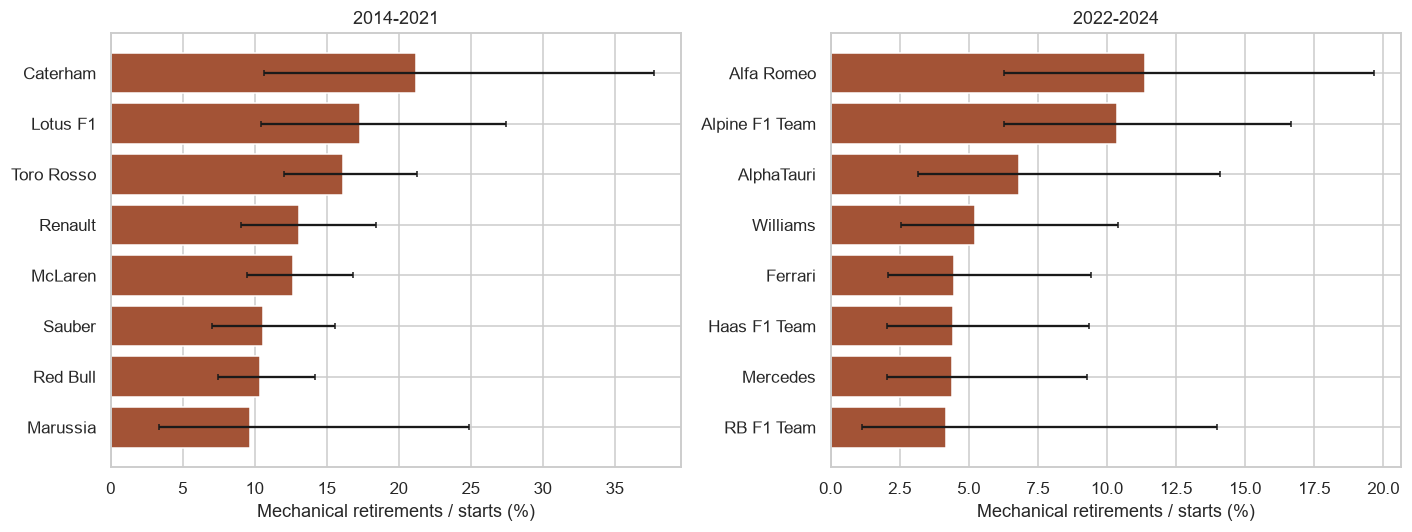

Ambiguous status rows:
     status  category  starts
   Retired ambiguous      49
     Wheel ambiguous      11
  Puncture ambiguous       7
      Tyre ambiguous       4
 Undertray ambiguous       4
Front wing ambiguous       3
 Rear wing ambiguous       3
    Damage ambiguous       2
 Technical ambiguous       2
Vibrations ambiguous       2
    Debris ambiguous       1
      Seat ambiguous       1
Top rates:
  constructorId    constructor  starts  mechanical  ambiguous     rate  sensitivity_upper      low     high  ranking_eligible
           207       Caterham      33           7          3 0.212121           0.303030 0.106760 0.377516              True
           208       Lotus F1      75          13          5 0.173333           0.240000 0.104191 0.274308              True
             5     Toro Rosso     242          39          5 0.161157           0.181818 0.120187 0.212716              True
             4        Renault     199          26          5 0.130653           0.15577

**Answer Q3.** Among constructors with at least 20 starts in each era, **Caterham** led 2014–2021 (7/33, 21.2%) and **Alfa Romeo** led 2022–2024 (10/88, 11.4%). The numerator counts explicit component failures; ambiguous statuses stay in the race-start denominator and are listed above with sensitivity rates. Status is post-race data used for this analysis only, never for prediction.

In [10]:
mechanical_statuses = {
 "Engine","Brakes","Gearbox","Power Unit","Suspension","Hydraulics","Electrical",
 "Power loss","Oil leak","Overheating","Mechanical","Water pressure","Turbo","ERS",
 "Exhaust","Battery","Fuel pressure","Water leak","Electronics","Transmission",
 "Wheel nut","Radiator","Oil pressure","Clutch","Throttle","Driveshaft","Steering",
 "Fuel leak","Drivetrain","Fuel system","Brake duct","Spark plugs","Cooling system",
 "Water pump","Fuel pump","Differential"}
nonmechanical_statuses = {"Collision","Accident","Collision damage","Spun off", "Disqualified",
    "Excluded","Withdrew","Illness","Injury","Injured","Fatal accident","Safety concerns",
    "Did not qualify","Did not prequalify","107% Rule","Out of fuel"}
def status_category(status):
    if status == "Finished" or re.fullmatch(r"\+\d+ Laps?", str(status)):
        return "finished"
    if status in mechanical_statuses:
        return "mechanical"
    if status in nonmechanical_statuses:
        return "other known"
    return "ambiguous"

q3 = starts.loc[starts.year.between(2014,2024)].merge(
    clean["status"][["statusId","status"]],on="statusId",validate="many_to_one")
q3 = q3.merge(clean["constructors"][["constructorId","name"]].rename(columns={"name":"constructor"}),
              on="constructorId",validate="many_to_one")
q3["era"] = np.where(q3.year<=2021,"2014-2021","2022-2024")
q3["category"] = q3.status.map(status_category)
status_map=save_table("q3_status_mapping",q3.groupby(["status","category"]).size().rename("starts").reset_index()
    .sort_values(["category","starts"],ascending=[True,False]))
q3_rates=q3.groupby(["era","constructorId","constructor"]).agg(
    starts=("driverId","size"),mechanical=("category",lambda x:int((x=="mechanical").sum())),
    ambiguous=("category",lambda x:int((x=="ambiguous").sum()))).reset_index()
q3_rates["rate"]=q3_rates.mechanical/q3_rates.starts
q3_rates["sensitivity_upper"]=(q3_rates.mechanical+q3_rates.ambiguous)/q3_rates.starts
q3_rates[["low","high"]]=np.array([proportion_confint(k,n,method="wilson")
    for k,n in zip(q3_rates.mechanical,q3_rates.starts)])
q3_rates["ranking_eligible"]=q3_rates.starts>=20
q3_rates=save_table("q3_mechanical_rates",q3_rates.sort_values(["era","rate"],ascending=[True,False]))
fig, axes=plt.subplots(1,2,figsize=(13,5))
for ax,era in zip(axes,["2014-2021","2022-2024"]):
    top=q3_rates.loc[(q3_rates.era==era)&q3_rates.ranking_eligible].nlargest(8,["rate","starts"]).sort_values("rate")
    ax.barh(top.constructor,100*top.rate,xerr=[100*(top.rate-top.low),100*(top.high-top.rate)],
            color="#a35336",capsize=2)
    ax.set_xlabel("Mechanical retirements / starts (%)");ax.set_title(era)
save_plot("07_q3_mechanical_by_era")
q3_summary={"top_by_era":{era:q3_rates.loc[(q3_rates.era==era)&q3_rates.ranking_eligible]
    .sort_values(["rate","starts"],ascending=False).head(3)[
      ["constructor","rate","starts","mechanical","ambiguous","sensitivity_upper","low","high"]].to_dict("records")
    for era in ["2014-2021","2022-2024"]},
    "ambiguous_starts":int((q3.category=="ambiguous").sum()),
    "category_counts":q3.category.value_counts().to_dict()}
SUMMARY["questions"]["q3"]=q3_summary
print("Ambiguous status rows:\n",status_map.query("category=='ambiguous'").to_string(index=False))
print("Top rates:\n",q3_rates.loc[q3_rates.ranking_eligible].groupby("era",group_keys=False)
      .apply(lambda g:g.nlargest(5,"rate"),include_groups=False).to_string(index=False))
if "ipykernel" in sys.modules:
    a,b=[q3_summary["top_by_era"][era][0] for era in ["2014-2021","2022-2024"]]
    display(Markdown(f"**Answer Q3.** Among constructors with at least 20 starts in each era, "
        f"**{a['constructor']}** led 2014–2021 ({a['mechanical']}/{a['starts']}, {a['rate']:.1%}) "
        f"and **{b['constructor']}** led 2022–2024 ({b['mechanical']}/{b['starts']}, {b['rate']:.1%}). "
        "The numerator counts explicit component failures; ambiguous statuses stay in the "
        "race-start denominator and are listed above with sensitivity rates. Status is post-race "
        "data used for this analysis only, never for prediction."))

## 7. Leakage-safe driver–race modeling table
The target comes from the **current** race's final `positionOrder`, but no
current-race outcome enters a predictor. `results.grid` is allowed because
it records the grid fixed before the race. All form uses earlier race IDs:
driver form shifts before rolling; constructor form first aggregates the two
cars at each *past race*, then shifts the constructor-race series. Standings
are post-race tables, so an as-of join takes the latest round **strictly
earlier** in the same season. Earlier test-race results may inform *later*
test-race form, as they would be public at that later prediction cutoff;
fitted model parameters never use test labels.

In [11]:
features = starts[["raceId","driverId","constructorId","circuitId","year","round","date",
                   "grid","positionOrder","podium"]].copy()
features=features.merge(clean["qualifying"][["raceId","driverId","position"]].rename(
    columns={"position":"qual_position"}),on=["raceId","driverId"],how="left",validate="one_to_one")
qual_counts=clean["qualifying"].groupby("raceId").size().rename("qualifying_field_size")
features=features.merge(qual_counts,on="raceId",how="left",validate="many_to_one")
features["grid_position"]=features.grid.mask(features.grid==0)
features["pitlane_start"]=(features.grid==0).astype(int)
features["grid_delta"]=features.grid_position-features.qual_position
features["qual_missing"]=features.qual_position.isna().astype(int)

features["prior_finish_fraction_source"]=features.positionOrder / features.groupby("raceId").driverId.transform("size")
features=features.sort_values(["year","round","raceId","driverId"]).reset_index(drop=True)
features["driver_prior_starts"]=features.groupby("driverId").cumcount()
features["driver_podium_last5"]=features.groupby("driverId").podium.transform(
    lambda s:s.shift(1).rolling(5,min_periods=1).mean())
features["driver_finish_last5"]=features.groupby("driverId").prior_finish_fraction_source.transform(
    lambda s:s.shift(1).rolling(5,min_periods=1).mean())

ctor_race=features.groupby(["constructorId","raceId","year","round"],as_index=False).agg(
    constructor_race_podium=("podium","mean"),
    constructor_race_finish=("prior_finish_fraction_source","mean"))
ctor_race=ctor_race.sort_values(["constructorId","year","round","raceId"]).reset_index(drop=True)
ctor_race["constructor_prior_races"]=ctor_race.groupby("constructorId").cumcount()
ctor_race["constructor_podium_last5"]=ctor_race.groupby("constructorId").constructor_race_podium.transform(
    lambda s:s.shift(1).rolling(5,min_periods=1).mean())
ctor_race["constructor_finish_last5"]=ctor_race.groupby("constructorId").constructor_race_finish.transform(
    lambda s:s.shift(1).rolling(5,min_periods=1).mean())
features=features.merge(ctor_race[["constructorId","raceId","constructor_prior_races",
    "constructor_podium_last5","constructor_finish_last5"]],
    on=["constructorId","raceId"],validate="many_to_one")

def add_prior_standings(left, standings_name, entity_col, prefix):
    right=clean[standings_name][["raceId",entity_col,"points","position"]].merge(
        race_info[["raceId","year","round"]],on="raceId",validate="many_to_one")
    right=right.rename(columns={"round":"source_round","points":f"{prefix}_prev_points",
                                "position":f"{prefix}_prev_rank"})
    assert not right.duplicated(["year","source_round",entity_col]).any()
    tmp=left.reset_index(names="original_index").sort_values("round")
    right=right.sort_values("source_round")
    joined=pd.merge_asof(tmp,right[["year",entity_col,"source_round",f"{prefix}_prev_points",
            f"{prefix}_prev_rank"]],left_on="round",right_on="source_round",
            by=["year",entity_col],direction="backward",allow_exact_matches=False)
    assert (joined.source_round.dropna()<joined.loc[joined.source_round.notna(),"round"]).all()
    joined=joined.sort_values("original_index").drop(columns="original_index").reset_index(drop=True)
    return joined.rename(columns={"source_round":f"{prefix}_source_round"})

features=add_prior_standings(features,"driver_standings","driverId","driver")
features=add_prior_standings(features,"constructor_standings","constructorId","constructor")
features["driver_standing_missing"]=features.driver_prev_rank.isna().astype(int)
features["constructor_standing_missing"]=features.constructor_prev_rank.isna().astype(int)
assert features.loc[features["round"]==1,["driver_prev_rank","constructor_prev_rank"]].isna().all().all()

driver_context=clean["drivers"][["driverId","dob","nationality"]].copy()
driver_context["driver_country"]=driver_context.nationality.str.strip().map(nationality_country)
circuit_context=clean["circuits"][["circuitId","country"]].copy()
circuit_context["circuit_country"]=circuit_context.country.map(canon_country)
features=features.merge(driver_context[["driverId","dob","driver_country"]],on="driverId",validate="many_to_one")
features=features.merge(circuit_context[["circuitId","circuit_country"]],on="circuitId",validate="many_to_one")
features["age_years"]=(features.date-features.dob).dt.days/365.25
features["is_home"]=np.where(features.driver_country.notna(),
                              (features.driver_country==features.circuit_country).astype(float),np.nan)
features["race_round"]=features["round"]

FEATURE_GROUPS={
 "Grid":["grid_position","pitlane_start"],
 "Qualifying":["qual_position","grid_delta","qual_missing"],
 "Driver form":["driver_prior_starts","driver_podium_last5","driver_finish_last5"],
 "Constructor form":["constructor_prior_races","constructor_podium_last5","constructor_finish_last5"],
 "Standings":["driver_prev_rank","driver_prev_points","constructor_prev_rank",
              "constructor_prev_points","driver_standing_missing","constructor_standing_missing"],
 "Context":["qualifying_field_size","age_years","race_round","is_home"]}
FEATURES=[col for group in FEATURE_GROUPS.values() for col in group]
assert len(FEATURES)==len(set(FEATURES))
FORBIDDEN={"positionOrder","position","positionText","points","laps","time","milliseconds",
           "fastestLap","fastestLapTime","fastestLapSpeed","statusId","podium"}
assert not FORBIDDEN.intersection(FEATURES)
assert features.loc[features.driver_prior_starts==0,["driver_podium_last5","driver_finish_last5"]].isna().all().all()
assert features.loc[features.constructor_prior_races==0,["constructor_podium_last5","constructor_finish_last5"]].isna().all().all()
assert not features.duplicated(["raceId","driverId"]).any()

# Explicit same-race leakage check: both cars of a constructor must get the
# same prior constructor form, regardless of their current results.
same_race_form=features.groupby(["raceId","constructorId"])[
    ["constructor_podium_last5","constructor_finish_last5"]].nunique(dropna=False)
assert same_race_form.max().max()==1
model_df=features.loc[features.year.between(2003,2024),
    ["raceId","driverId","constructorId","year","round","podium"]+FEATURES].copy()
assert not model_df.duplicated(["raceId","driverId"]).any()
assert model_df.groupby("raceId").podium.sum().max()<=3
save_table("modeling_table",model_df)
print("Modeling rows:",len(model_df),"| features:",len(FEATURES),"| podium rate:",round(model_df.podium.mean(),3))
SUMMARY["modeling"].update({"rows":len(model_df),"features":FEATURES,
    "feature_groups":FEATURE_GROUPS,"podium_rate":float(model_df.podium.mean())})

Modeling rows: 8905 | features: 21 | podium rate: 0.144


## 8. Feature evidence and chronological split
The 2003 cutoff follows the raw qualifying-coverage plot: 2002 is sparse,
while 2003 onward is essentially complete. This is a hypothesis-driven
choice about measurement quality, not a test-set optimization. The model
includes grid (strong visual relationship), qualifying/grid change (penalty
information), recent driver and car form, previous standings (competitive
context), and pre-race context. Grid, form and standings can be correlated;
the later controlled ablation measures whether each group helps. Current
race status and results only supply the label or *earlier-race* history.

     split     years  rows  races  podium_rate
     train 2003–2019  6780    321     0.142035
validation 2020–2021   774     39     0.151163
      test 2022–2024  1351     68     0.150999


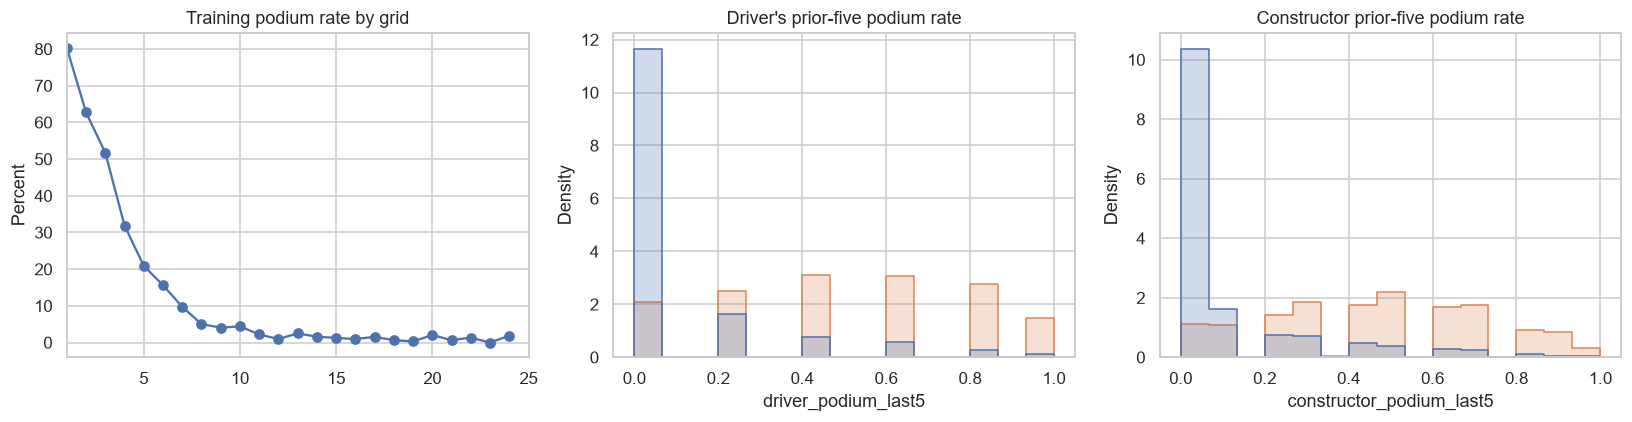

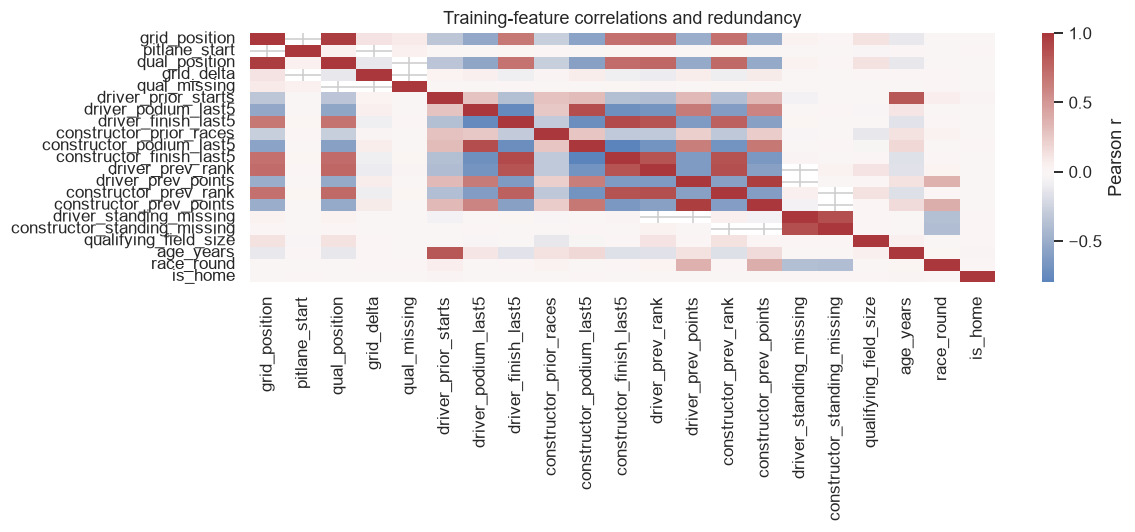

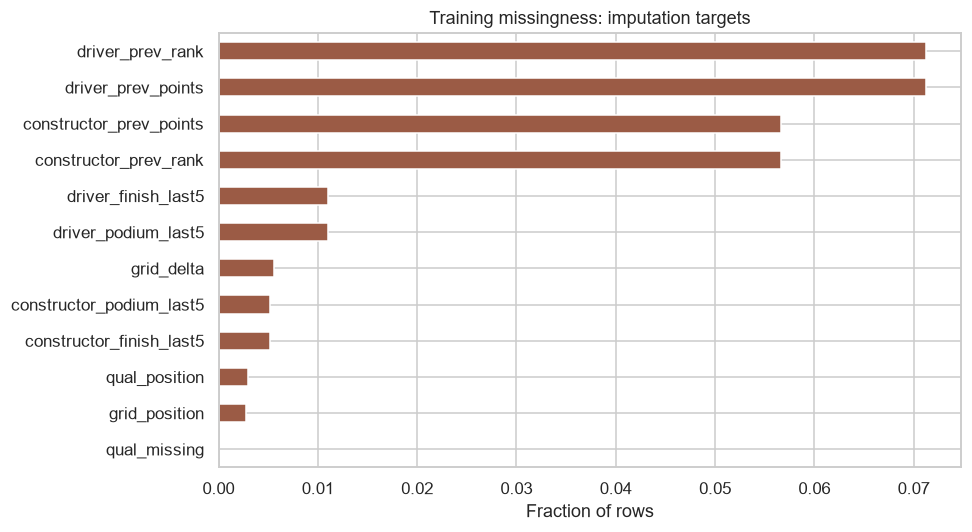

           group                                                                                                                                      fields                                                                     reason                             cutoff
            Grid                                                                                                                grid_position, pitlane_start  Grid-position EDA shows steep podium gradient; pit-lane zero is separate. pre-race or strictly earlier races
      Qualifying                                                                                                     qual_position, grid_delta, qual_missing Qualifying and grid can differ after penalties; coverage measured by year. pre-race or strictly earlier races
     Driver form                                                                               driver_prior_starts, driver_podium_last5, driver_finish_last5           Earlier-driver podium/finish his

In [12]:
train=model_df.loc[model_df.year<=2019].copy()
val=model_df.loc[model_df.year.between(2020,2021)].copy()
test=model_df.loc[model_df.year>=2022].copy()
assert train.year.max()<val.year.min()<test.year.min()
assert not (set(train.raceId)&set(val.raceId) or set(train.raceId)&set(test.raceId) or set(val.raceId)&set(test.raceId))
split_table=save_table("split_summary",pd.DataFrame([
    {"split":name,"years":f"{df.year.min()}–{df.year.max()}","rows":len(df),
     "races":df.raceId.nunique(),"podium_rate":df.podium.mean()}
    for name,df in [("train",train),("validation",val),("test",test)]]))
print(split_table.to_string(index=False))
X_train,y_train=train[FEATURES],train.podium.to_numpy()
X_val,y_val=val[FEATURES],val.podium.to_numpy()
X_test,y_test=test[FEATURES],test.podium.to_numpy()
feature_missing=train[FEATURES].isna().mean().sort_values(ascending=False)
save_table("feature_missingness",feature_missing.rename_axis("feature").reset_index(name="fraction_missing"))
fig,axes=plt.subplots(1,3,figsize=(15,4))
grid_rates=train.loc[train.grid_position.notna()].groupby("grid_position").podium.agg(["mean","size"])
axes[0].plot(grid_rates.index,100*grid_rates["mean"],marker="o");axes[0].set_xlim(1,25)
axes[0].set_title("Training podium rate by grid");axes[0].set_ylabel("Percent")
for ax,col,title in [(axes[1],"driver_podium_last5","Driver's prior-five podium rate"),
                      (axes[2],"constructor_podium_last5","Constructor prior-five podium rate")]:
    sns.histplot(data=train,x=col,hue="podium",stat="density",common_norm=False,
                 bins=15,element="step",ax=ax,legend=False)
    ax.set_title(title)
save_plot("08_feature_evidence")
fig,ax=plt.subplots(figsize=(11,5))
sns.heatmap(train[FEATURES].corr(),cmap="vlag",center=0,ax=ax,cbar_kws={"label":"Pearson r"})
ax.set_title("Training-feature correlations and redundancy")
save_plot("09_feature_correlations")
fig,ax=plt.subplots(figsize=(9,5))
feature_missing.head(12).sort_values().plot.barh(ax=ax,color="#9b5b45")
ax.set_title("Training missingness: imputation targets");ax.set_xlabel("Fraction of rows")
save_plot("10_feature_missingness")
feature_evidence=pd.DataFrame([
    {"group":group,"fields":", ".join(cols),"reason":reason,
     "cutoff":"pre-race or strictly earlier races"}
    for group,cols,reason in [
        ("Grid",FEATURE_GROUPS["Grid"],"Grid-position EDA shows steep podium gradient; pit-lane zero is separate."),
        ("Qualifying",FEATURE_GROUPS["Qualifying"],"Qualifying and grid can differ after penalties; coverage measured by year."),
        ("Driver form",FEATURE_GROUPS["Driver form"],"Earlier-driver podium/finish histories may capture current form."),
        ("Constructor form",FEATURE_GROUPS["Constructor form"],"Prior car/team race outcomes may capture competitiveness."),
        ("Standings",FEATURE_GROUPS["Standings"],"Only latest previous-round standing, never same-race standing."),
        ("Context",FEATURE_GROUPS["Context"],"Field size, age, round and home status are known before lights out.")]])
save_table("feature_justification",feature_evidence)
print(feature_evidence.to_string(index=False))

## 9. Preprocessing and two order experiments
No transform is fitted on validation or test data. For the first controlled
experiment, `log1p` and mean imputation trade order on nonnegative previous
standings points; the two orders yield log(mean) versus mean(log) for missing
rows. For the second, training-quantile clipping and mean imputation trade
order on continuous form, age, and grid-change fields. The input columns,
logistic model, and split stay fixed. Validation PR-AUC chooses each order.
This tests a real preprocessing sequence without deliberately leaking data.

In [13]:
class NumericPreprocessor(BaseEstimator, TransformerMixin):
    """Train-fitted preprocessing with explicit, reproducible operation order."""
    def __init__(self, feature_names, log_before=True, clip_before=True, scale=True):
        self.feature_names=feature_names
        self.log_before=log_before
        self.clip_before=clip_before
        self.scale=scale

    def _array(self, X):
        if isinstance(X,pd.DataFrame):
            return X.loc[:,self.feature_names].to_numpy(dtype=float,copy=True)
        return np.asarray(X,dtype=float).copy()

    def _apply_clip(self, a):
        for j,lo,hi in self.clip_bounds_:
            a[:,j]=np.clip(a[:,j],lo,hi)
        return a

    def _apply_log(self,a):
        for j in self.log_indices_:
            a[:,j]=np.log1p(np.clip(a[:,j],0,None))
        return a

    def _pre(self,a):
        if self.clip_before: self._apply_clip(a)
        if self.log_before: self._apply_log(a)
        return a

    def _post(self,a):
        if not self.log_before: self._apply_log(a)
        if not self.clip_before: self._apply_clip(a)
        return a

    def fit(self,X,y=None):
        self.feature_names_=list(self.feature_names)
        self.log_indices_=[self.feature_names_.index(c) for c in
            ["driver_prev_points","constructor_prev_points"] if c in self.feature_names_]
        self.clip_indices_=[self.feature_names_.index(c) for c in
            ["driver_finish_last5","constructor_finish_last5","grid_delta","age_years"]
            if c in self.feature_names_]
        a=self._array(X)
        self.clip_bounds_=[]
        if self.clip_before:
            for j in self.clip_indices_:
                good=a[:,j][np.isfinite(a[:,j])]
                self.clip_bounds_.append((j,*np.quantile(good,[.01,.99])))
        a=self._pre(a)
        self.imputer_=SimpleImputer(strategy="mean",keep_empty_features=True).fit(a)
        a=self.imputer_.transform(a)
        if not self.clip_before:
            for j in self.clip_indices_:
                self.clip_bounds_.append((j,*np.quantile(a[:,j],[.01,.99])))
        a=self._post(a)
        self.scaler_=StandardScaler().fit(a) if self.scale else None
        return self

    def transform(self,X):
        a=self._pre(self._array(X))
        a=self.imputer_.transform(a)
        a=self._post(a)
        if self.scaler_ is not None: a=self.scaler_.transform(a)
        assert np.isfinite(a).all(),"Preprocessing must return finite values"
        return a

def threshold_for_f1(y,p):
    precision,recall,thresholds=precision_recall_curve(y,p)
    f=2*precision[:-1]*recall[:-1]/np.maximum(precision[:-1]+recall[:-1],1e-12)
    return float(thresholds[int(np.nanargmax(f))])

def score_probabilities(y,p,threshold):
    pred=(p>=threshold).astype(int)
    return {"roc_auc":float(roc_auc_score(y,p)),"pr_auc":float(average_precision_score(y,p)),
            "f1":float(f1_score(y,pred,zero_division=0)),
            "precision":float(precision_score(y,pred,zero_division=0)),
            "recall":float(recall_score(y,pred,zero_division=0))}

def logistic_with_order(log_before,clip_before):
    pipe=Pipeline([("prep",NumericPreprocessor(FEATURES,log_before=log_before,
                                                 clip_before=clip_before)),
                   ("model",LogisticRegression(C=1,max_iter=2000,random_state=SEED))])
    pipe.fit(X_train,y_train)
    p=pipe.predict_proba(X_val)[:,1]
    threshold=threshold_for_f1(y_val,p)
    return pipe,{"log_before_impute":log_before,"clip_before_impute":clip_before,
                 "threshold":threshold,**score_probabilities(y_val,p,threshold)}

### 9.1 Experiment A: log transform before vs after mean imputation
Only the order of these two operations changes. The logistic baseline and
feature list are fixed; each run below reports its own validation scores.

In [14]:
order_trials=[]
for log_before in [True,False]:
    _,row=logistic_with_order(log_before,True)
    row["experiment"]="log/impute"
    order_trials.append(row)
    print("log before impute:",log_before,"validation PR-AUC",round(row["pr_auc"],4),
          "F1",round(row["f1"],4))
best_log=max([r for r in order_trials if r["experiment"]=="log/impute"],key=lambda r:r["pr_auc"])["log_before_impute"]

log before impute: True validation PR-AUC 0.7234 F1 0.7177
log before impute: False validation PR-AUC 0.7237 F1 0.7177


### 9.2 Experiment B: clipping before vs after mean imputation
The chosen log order from Experiment A is held fixed. Clipping quantiles
are fitted from training rows only in either variant.

In [15]:
for clip_before in [True,False]:
    _,row=logistic_with_order(best_log,clip_before)
    row["experiment"]="clip/impute"
    order_trials.append(row)
    print("clip before impute:",clip_before,"validation PR-AUC",round(row["pr_auc"],4),
          "F1",round(row["f1"],4))
best_clip=max([r for r in order_trials if r["experiment"]=="clip/impute"],key=lambda r:r["pr_auc"])["clip_before_impute"]

clip before impute: True validation PR-AUC 0.7237 F1 0.7177


clip before impute: False validation PR-AUC 0.7237 F1 0.7177


### 9.3 Order comparison and distribution effects

 log_before_impute  clip_before_impute  threshold  roc_auc   pr_auc       f1  precision   recall  experiment
              True                True   0.318780 0.928268 0.723397 0.717742   0.679389 0.760684  log/impute
             False                True   0.318587 0.928294 0.723662 0.717742   0.679389 0.760684  log/impute
             False                True   0.318587 0.928294 0.723662 0.717742   0.679389 0.760684 clip/impute
             False               False   0.318537 0.928307 0.723667 0.717742   0.679389 0.760684 clip/impute
Chosen preprocessing: log before impute = False ; clip before impute = False


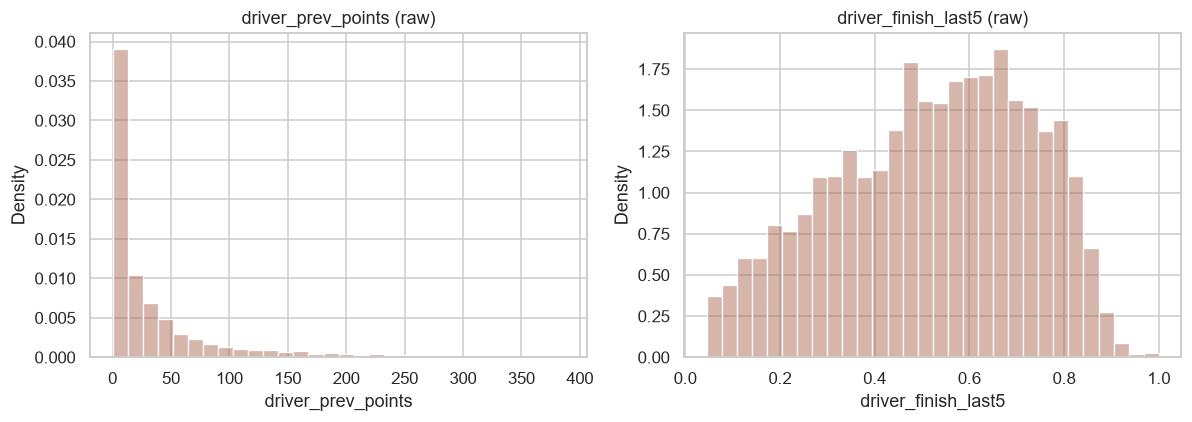

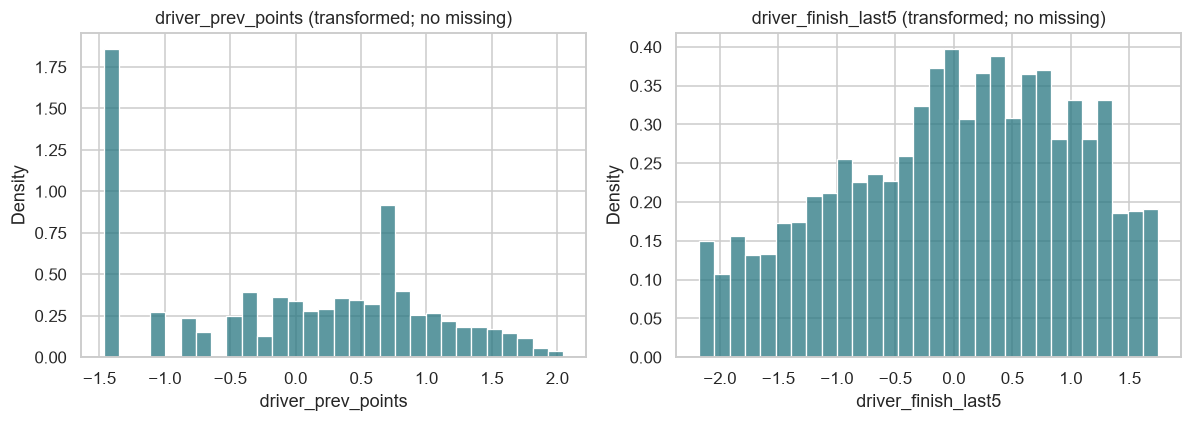

In [16]:
order_table=save_table("preprocessing_order_trials",pd.DataFrame(order_trials))
print(order_table.to_string(index=False))
print("Chosen preprocessing: log before impute =",best_log,"; clip before impute =",best_clip)
SUMMARY["modeling"]["preprocessing_order"]={"trials":order_table.to_dict("records"),
    "selected_log_before_impute":bool(best_log),"selected_clip_before_impute":bool(best_clip)}

illustration=NumericPreprocessor(FEATURES,log_before=best_log,clip_before=best_clip).fit(X_train)
transformed=pd.DataFrame(illustration.transform(X_train),columns=FEATURES)
distribution_table=save_table("preprocessing_effect",pd.DataFrame([
    {"feature":c,"raw_min":float(X_train[c].min()),"raw_max":float(X_train[c].max()),
     "raw_missing":int(X_train[c].isna().sum()),
     "transformed_min":float(transformed[c].min()),"transformed_max":float(transformed[c].max()),
     "transformed_missing":int(transformed[c].isna().sum())}
    for c in FEATURES]))
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,c in zip(axes,["driver_prev_points","driver_finish_last5"]):
    sns.histplot(X_train[c].dropna(),bins=30,ax=ax,color="#a45c44",alpha=.45,label="raw",stat="density")
    ax.set_title(c+" (raw)")
save_plot("11_preprocessing_raw_distributions")
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,c in zip(axes,["driver_prev_points","driver_finish_last5"]):
    sns.histplot(transformed[c],bins=30,ax=ax,color="#277681",stat="density")
    ax.set_title(c+" (transformed; no missing)")
save_plot("12_preprocessing_transformed_distributions")

## 10. Statistical models and one-hidden-layer neural network
Four families and a predeclared small parameter grid make more than three
distinct attempts. All use the exact `FEATURES` list and training rows.
The primary metric is average precision (reported as PR-AUC/AP) because
podiums are uncommon; F1 is secondary and selects a probability threshold
on validation data. ROC-AUC, precision, and recall are also reported. The
test years are scored **only after** all hyperparameters, preprocessing
orders, thresholds, and the winning family are frozen.

**How the models work and where they can fail.** Logistic regression fits a
linear log-odds boundary and is an interpretable baseline, but it can miss
nonlinear interactions. A random forest averages bagged trees and can learn
interactions, but its training fit can be optimistic. Histogram gradient
boosting adds trees sequentially and is powerful but sensitive to tuning and
changing eras. The MLP is a one-hidden-layer feedforward neural network
trained by backpropagation; it needs scaled inputs and may converge slowly
or vary with initialization. All four face the 2022 rules shift.

In [17]:
model_candidates={
 "Logistic regression":[
   {"C":c,"max_iter":2000,"random_state":SEED} for c in [.1,1,10]],
 "Random forest":[
   {"n_estimators":180,"min_samples_leaf":leaf,"max_features":"sqrt",
    "n_jobs":-1,"random_state":SEED} for leaf in [3,10]],
 "Gradient boosting":[
   {"max_iter":180,"learning_rate":.05,"max_leaf_nodes":leaves,
    "l2_regularization":1,"random_state":SEED} for leaves in [15,31]],
 "Shallow neural network":[
   {"hidden_layer_sizes":(hidden,),"alpha":.001,"max_iter":160,
    "batch_size":256,"random_state":SEED,"early_stopping":False} for hidden in [32,64]]}
model_classes={"Logistic regression":LogisticRegression,"Random forest":RandomForestClassifier,
               "Gradient boosting":HistGradientBoostingClassifier,"Shallow neural network":MLPClassifier}
attempts=[]
best_by_family={}
def fit_family(family):
    variants=model_candidates[family]
    for params in variants:
        pipeline=Pipeline([("prep",NumericPreprocessor(FEATURES,log_before=best_log,
                                                       clip_before=best_clip)),
                           ("model",model_classes[family](**params))])
        pipeline.fit(X_train,y_train)
        p_val=pipeline.predict_proba(X_val)[:,1]
        threshold=threshold_for_f1(y_val,p_val)
        metrics=score_probabilities(y_val,p_val,threshold)
        attempt={"family":family,"parameters":str(params),"threshold":threshold,**metrics}
        attempts.append(attempt)
        if family not in best_by_family or metrics["pr_auc"]>best_by_family[family]["val_pr_auc"]:
            best_by_family[family]={"pipeline":pipeline,"params":params,"threshold":threshold,
                                    "val_pr_auc":metrics["pr_auc"],"val_f1":metrics["f1"]}
        print(family,params,"validation PR-AUC",round(metrics["pr_auc"],4),"F1",round(metrics["f1"],4))

### 10.1 Baseline: logistic regression
The C=1 run is the simplest reference. C=0.1 and C=10 test stronger and
weaker regularization with the same rows and fields.

In [18]:
fit_family("Logistic regression")

Logistic regression {'C': 0.1, 'max_iter': 2000, 'random_state': 42} validation PR-AUC 0.7163 F1 0.7068
Logistic regression {'C': 1, 'max_iter': 2000, 'random_state': 42} validation PR-AUC 0.7237 F1 0.7177
Logistic regression {'C': 10, 'max_iter': 2000, 'random_state': 42} validation PR-AUC 0.7237 F1 0.7177


### 10.2 Statistical alternative: random forest
Compare two leaf-size settings against the logistic baseline.

In [19]:
fit_family("Random forest")

Random forest {'n_estimators': 180, 'min_samples_leaf': 3, 'max_features': 'sqrt', 'n_jobs': -1, 'random_state': 42} validation PR-AUC 0.6928 F1 0.716


Random forest {'n_estimators': 180, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'n_jobs': -1, 'random_state': 42} validation PR-AUC 0.7214 F1 0.7132


### 10.3 Statistical alternative: histogram gradient boosting
Compare two tree-complexity settings on the identical modeling table.

In [20]:
fit_family("Gradient boosting")

Gradient boosting {'max_iter': 180, 'learning_rate': 0.05, 'max_leaf_nodes': 15, 'l2_regularization': 1, 'random_state': 42} validation PR-AUC 0.6855 F1 0.7186


Gradient boosting {'max_iter': 180, 'learning_rate': 0.05, 'max_leaf_nodes': 31, 'l2_regularization': 1, 'random_state': 42} validation PR-AUC 0.6632 F1 0.7034


### 10.4 Shallow feedforward neural network
Compare 32 and 64 hidden units in a single hidden layer; both use the same
scaled feature inputs. The loss curve is shown below.

In [21]:
fit_family("Shallow neural network")
trained_nn=best_by_family["Shallow neural network"]["pipeline"].named_steps["model"]
SUMMARY["modeling"]["nn_epoch_cap_reached"]=bool(trained_nn.n_iter_ >= trained_nn.max_iter)
if trained_nn.n_iter_ >= trained_nn.max_iter:
    print("Neural-network training reached the declared epoch cap; compare its validation scores and loss curve.")

Shallow neural network {'hidden_layer_sizes': (32,), 'alpha': 0.001, 'max_iter': 160, 'batch_size': 256, 'random_state': 42, 'early_stopping': False} validation PR-AUC 0.7187 F1 0.705


Shallow neural network {'hidden_layer_sizes': (64,), 'alpha': 0.001, 'max_iter': 160, 'batch_size': 256, 'random_state': 42, 'early_stopping': False} validation PR-AUC 0.6901 F1 0.7054
Neural-network training reached the declared epoch cap; compare its validation scores and loss curve.


### 10.5 Frozen model comparison on train, validation and unseen test
All parameter/threshold selections above use validation only. Only now are
the unseen 2022-2024 rows scored, once per selected family variant.

Selected: Logistic regression {'C': 10, 'max_iter': 2000, 'random_state': 42}
                 model      split  selected  threshold  roc_auc  pr_auc     f1  precision  recall
   Logistic regression      train      True     0.3164   0.9285  0.6860 0.6721     0.5960  0.7705
   Logistic regression validation      True     0.3164   0.9286  0.7237 0.7177     0.6794  0.7607
   Logistic regression       test      True     0.3164   0.9361  0.7085 0.6694     0.5786  0.7941
         Random forest      train     False     0.3018   0.9681  0.8393 0.7471     0.6575  0.8650
         Random forest validation     False     0.3018   0.9308  0.7214 0.7132     0.6525  0.7863
         Random forest       test     False     0.3018   0.9334  0.7076 0.6680     0.5690  0.8088
     Gradient boosting      train     False     0.4537   0.9716  0.8564 0.7721     0.7791  0.7653
     Gradient boosting validation     False     0.4537   0.9263  0.6855 0.7186     0.7281  0.7094
     Gradient boosting       test     Fa

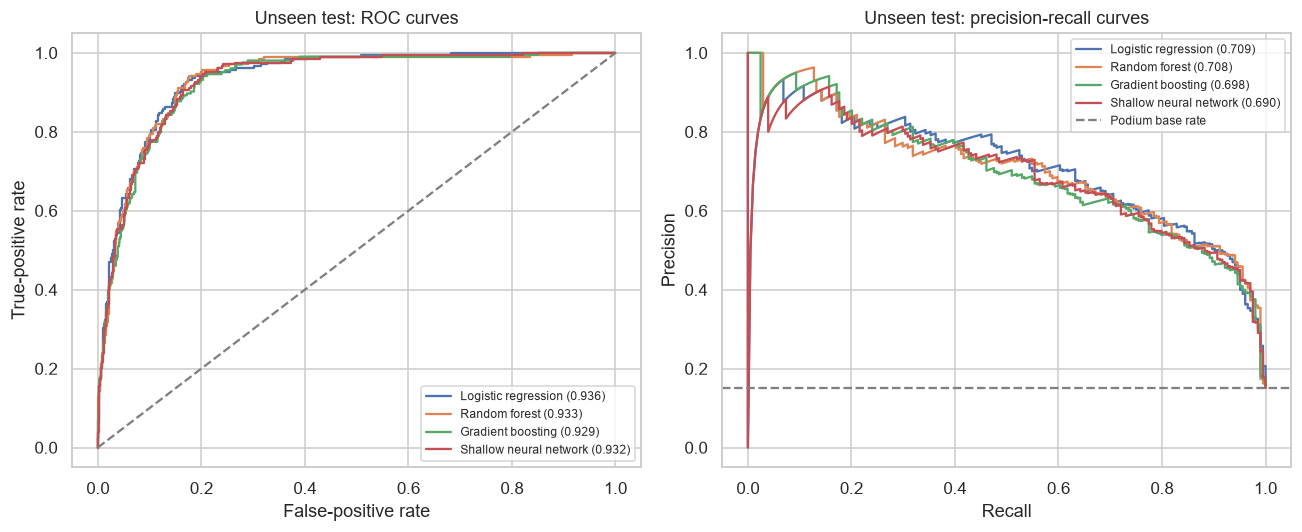

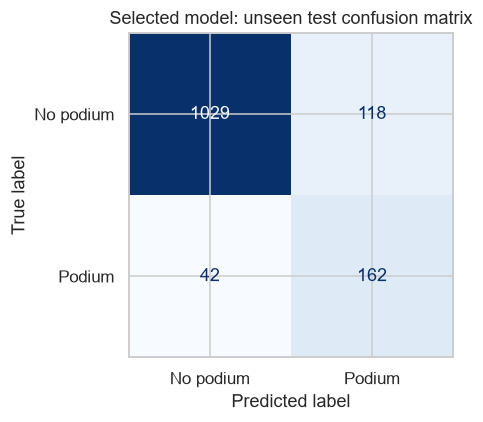

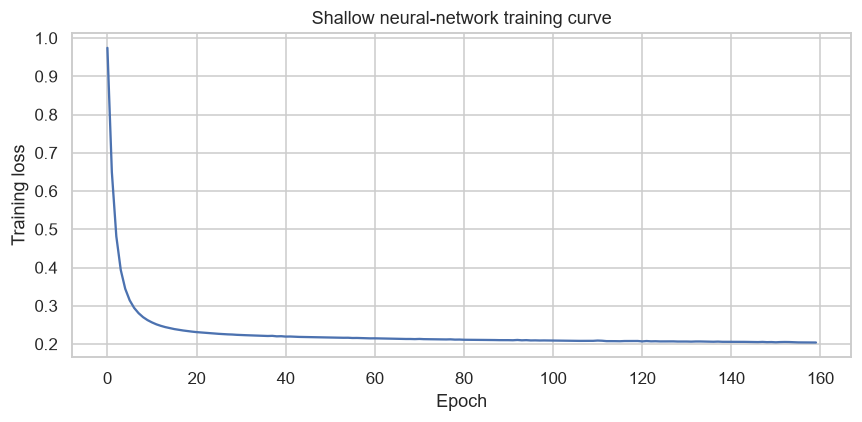

In [22]:
attempt_table=save_table("model_attempts",pd.DataFrame(attempts))
winner_family=max(best_by_family,key=lambda family:(best_by_family[family]["val_pr_auc"],
                                                   best_by_family[family]["val_f1"]))
winner=best_by_family[winner_family]
comparison_rows=[]
probabilities={}
for family,item in best_by_family.items():
    pipe=item["pipeline"]
    for split,X,y in [("train",X_train,y_train),("validation",X_val,y_val),("test",X_test,y_test)]:
        p=pipe.predict_proba(X)[:,1]
        probabilities[(family,split)]=p
        comparison_rows.append({"model":family,"split":split,"selected":family==winner_family,
            "threshold":item["threshold"],**score_probabilities(y,p,item["threshold"])})
comparison=save_table("model_comparison",pd.DataFrame(comparison_rows))
print("Selected:",winner_family,winner["params"])
print(comparison.round(4).to_string(index=False))
SUMMARY["modeling"].update({"winner":winner_family,"winner_parameters":str(winner["params"]),
    "threshold":winner["threshold"],"attempts":attempt_table.to_dict("records"),
    "comparison":comparison.to_dict("records")})

fig,axes=plt.subplots(1,2,figsize=(12,5))
for family in best_by_family:
    p=probabilities[(family,"test")]
    fpr,tpr,_=roc_curve(y_test,p)
    precision,recall,_=precision_recall_curve(y_test,p)
    auc=score_probabilities(y_test,p,best_by_family[family]["threshold"])
    axes[0].plot(fpr,tpr,label=f"{family} ({auc['roc_auc']:.3f})")
    axes[1].plot(recall,precision,label=f"{family} ({auc['pr_auc']:.3f})")
axes[0].plot([0,1],[0,1],"--",color="gray");axes[0].set_title("Unseen test: ROC curves")
axes[0].set_xlabel("False-positive rate");axes[0].set_ylabel("True-positive rate")
axes[1].axhline(y_test.mean(),ls="--",color="gray",label="Podium base rate")
axes[1].set_title("Unseen test: precision-recall curves")
axes[1].set_xlabel("Recall");axes[1].set_ylabel("Precision")
for ax in axes:ax.legend(fontsize=8)
save_plot("13_model_curves_test")
fig,ax=plt.subplots(figsize=(5,4))
p_winner=probabilities[(winner_family,"test")]
ConfusionMatrixDisplay(confusion_matrix(y_test,p_winner>=winner["threshold"]),
    display_labels=["No podium","Podium"]).plot(ax=ax,colorbar=False,cmap="Blues")
ax.set_title("Selected model: unseen test confusion matrix")
save_plot("14_test_confusion")
if winner_family=="Shallow neural network":
    fig,ax=plt.subplots(figsize=(8,4))
    ax.plot(winner["pipeline"].named_steps["model"].loss_curve_)
    ax.set_xlabel("Epoch");ax.set_ylabel("Training loss")
    ax.set_title("Neural-network training curve (validation metrics above)")
    save_plot("15_neural_training")
else:
    nn=best_by_family["Shallow neural network"]["pipeline"].named_steps["model"]
    fig,ax=plt.subplots(figsize=(8,4));ax.plot(nn.loss_curve_)
    ax.set_xlabel("Epoch");ax.set_ylabel("Training loss")
    ax.set_title("Shallow neural-network training curve")
    save_plot("15_neural_training")

## 11. Feature-group ablation
Refit the selected model after removing each group, with the same training
rows, final preprocessing order, hyperparameters, and full-model threshold.
Compare validation PR-AUC and F1 with the full model; no test information
selects or interprets feature groups.

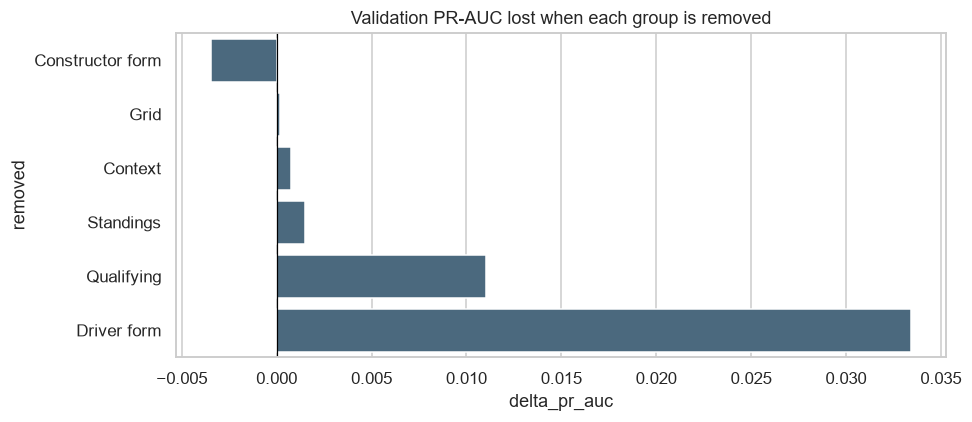

          removed  features  pr_auc     f1  delta_pr_auc
None (full model)        21  0.7237 0.7177        0.0000
             Grid        19  0.7235 0.7120        0.0002
       Qualifying        18  0.7126 0.6992        0.0110
      Driver form        18  0.6902 0.7008        0.0334
 Constructor form        18  0.7271 0.7097       -0.0035
        Standings        15  0.7222 0.7120        0.0015
          Context        17  0.7229 0.6967        0.0007


In [23]:
full_val=score_probabilities(y_val,probabilities[(winner_family,"validation")],winner["threshold"])
ablation_rows=[{"removed":"None (full model)","features":len(FEATURES),"pr_auc":full_val["pr_auc"],
                "f1":full_val["f1"],"delta_pr_auc":0.0}]
for group,cols in FEATURE_GROUPS.items():
    selected=[c for c in FEATURES if c not in cols]
    pipe=Pipeline([("prep",NumericPreprocessor(selected,log_before=best_log,clip_before=best_clip)),
                   ("model",model_classes[winner_family](**winner["params"]))])
    pipe.fit(X_train[selected],y_train)
    scores=score_probabilities(y_val,pipe.predict_proba(X_val[selected])[:,1],winner["threshold"])
    ablation_rows.append({"removed":group,"features":len(selected),"pr_auc":scores["pr_auc"],
                          "f1":scores["f1"],"delta_pr_auc":full_val["pr_auc"]-scores["pr_auc"]})
ablation=save_table("feature_group_ablation",pd.DataFrame(ablation_rows))
fig,ax=plt.subplots(figsize=(9,4))
sns.barplot(data=ablation.iloc[1:].sort_values("delta_pr_auc"),x="delta_pr_auc",y="removed",ax=ax,color="#436b86")
ax.axvline(0,color="black",lw=.8);ax.set_title("Validation PR-AUC lost when each group is removed")
save_plot("16_feature_ablation")
print(ablation.round(4).to_string(index=False))
SUMMARY["modeling"]["ablation"]=ablation.to_dict("records")

## 12. Model explanations
Permutation importance evaluates the selected **pipeline** on validation
rows, so it includes preprocessing. SHAP uses a bounded training background
and validation sample; LIME describes one complete unseen test input. All
three explain model reliance, not a causal effect of a driver or feature.
Correlated grid, qualifying, form and standings variables may share credit.

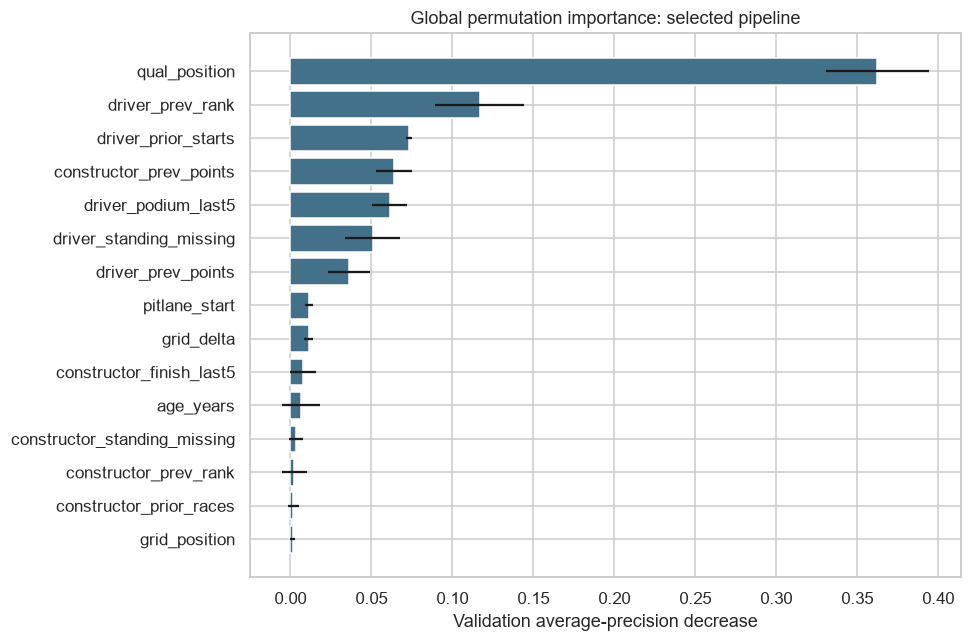

                     feature  importance_mean  importance_sd
               qual_position           0.3624         0.0319
            driver_prev_rank           0.1169         0.0276
         driver_prior_starts           0.0734         0.0019
     constructor_prev_points           0.0640         0.0113
         driver_podium_last5           0.0613         0.0108
     driver_standing_missing           0.0508         0.0168
          driver_prev_points           0.0361         0.0130
               pitlane_start           0.0116         0.0026
                  grid_delta           0.0112         0.0029
    constructor_finish_last5           0.0075         0.0081
                   age_years           0.0066         0.0117
constructor_standing_missing           0.0033         0.0044


In [24]:
selected_pipeline=winner["pipeline"]
perm=permutation_importance(selected_pipeline,X_val,y_val,scoring="average_precision",
                            n_repeats=3,random_state=SEED,n_jobs=1)
perm_table=save_table("permutation_importance",pd.DataFrame({
    "feature":FEATURES,"importance_mean":perm.importances_mean,
    "importance_sd":perm.importances_std}).sort_values("importance_mean",ascending=False))
fig,ax=plt.subplots(figsize=(9,6))
top_perm=perm_table.head(15).sort_values("importance_mean")
ax.barh(top_perm.feature,top_perm.importance_mean,xerr=top_perm.importance_sd,color="#44718a")
ax.set_xlabel("Validation average-precision decrease")
ax.set_title("Global permutation importance: selected pipeline")
save_plot("17_permutation_importance")
print(perm_table.head(12).round(4).to_string(index=False))

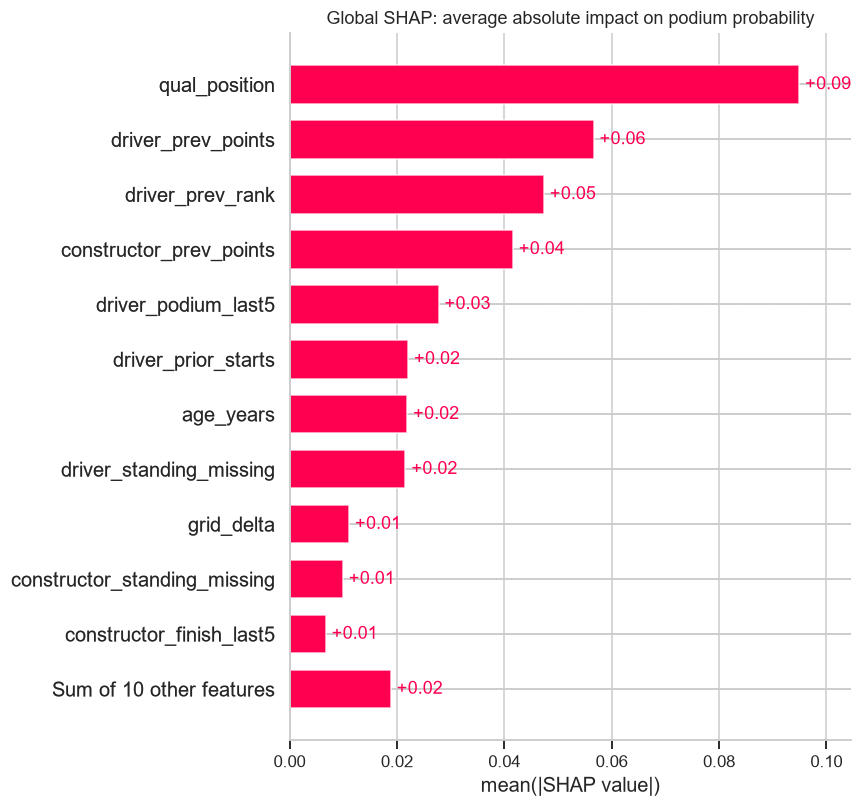

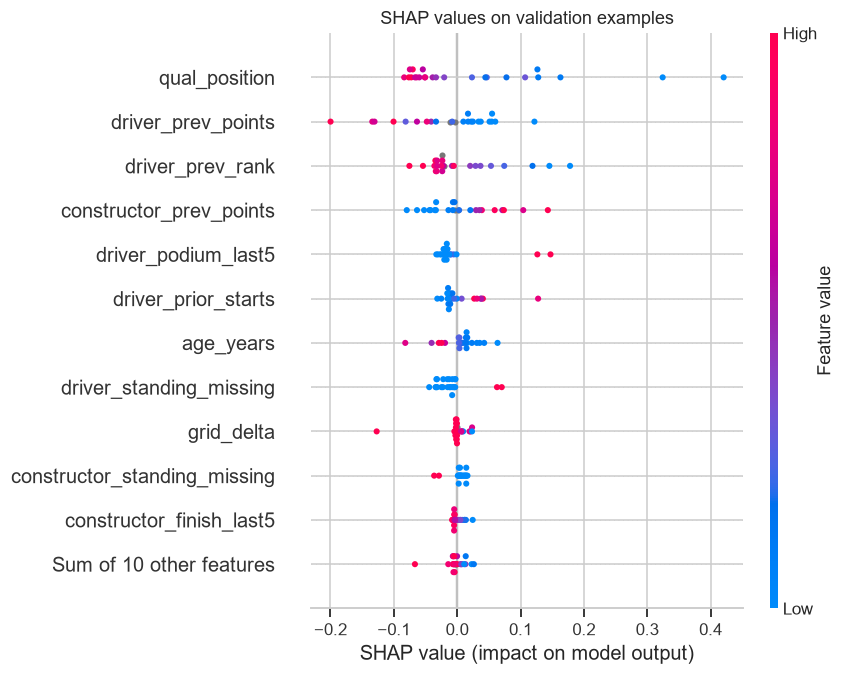

,feature,mean_absolute_shap
2,qual_position,0.094928
12,driver_prev_points,0.056633
11,driver_prev_rank,0.047379
14,constructor_prev_points,0.041592
6,driver_podium_last5,0.027762
5,driver_prior_starts,0.022076
18,age_years,0.021919
15,driver_standing_missing,0.021586
3,grid_delta,0.011093
16,constructor_standing_missing,0.009930


In [25]:
import shap
background=X_train.sample(n=min(30,len(X_train)),random_state=SEED)
explain_rows=X_val.sample(n=min(24,len(X_val)),random_state=SEED+1)
def predict_proba_one(data):
    frame=pd.DataFrame(data,columns=FEATURES)
    return selected_pipeline.predict_proba(frame)[:,1]

explainer=shap.Explainer(predict_proba_one,background,algorithm="permutation",
                        feature_names=FEATURES,seed=SEED)
shap_values=explainer(explain_rows,max_evals=2*len(FEATURES)+1,silent=True)
shap.plots.bar(shap_values,max_display=12,show=False)
plt.title("Global SHAP: average absolute impact on podium probability")
save_plot("18_shap_global")
shap.plots.beeswarm(shap_values,max_display=12,show=False)
plt.title("SHAP values on validation examples")
save_plot("19_shap_beeswarm")
shap_magnitude=pd.DataFrame({"feature":FEATURES,
    "mean_absolute_shap":np.abs(shap_values.values).mean(axis=0)}).sort_values("mean_absolute_shap",ascending=False)
save_table("shap_global",shap_magnitude)

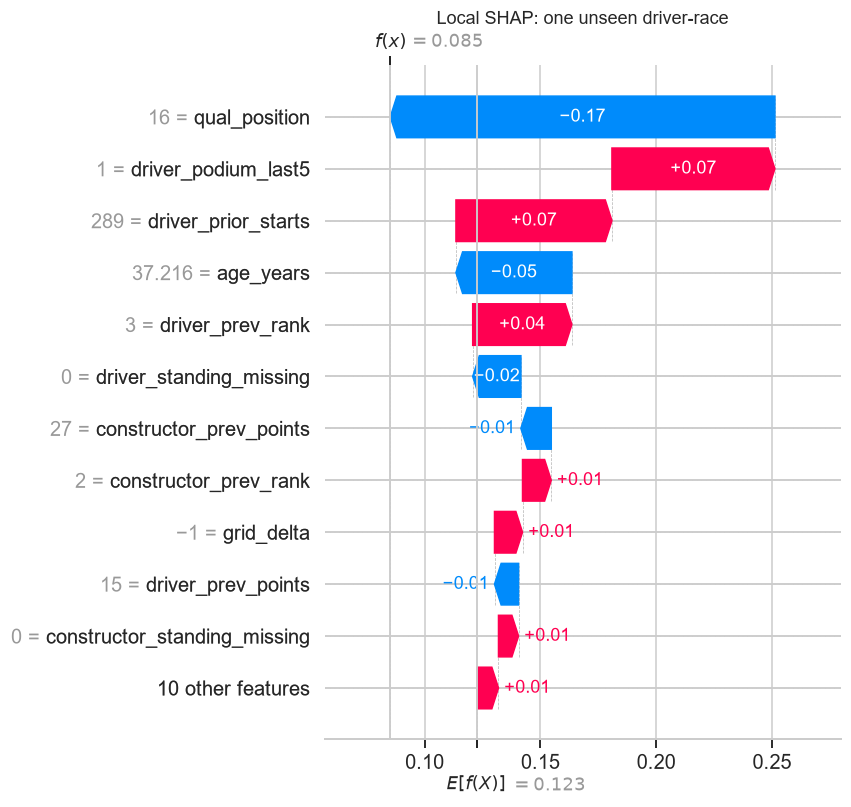

In [26]:
complete_candidates=X_test.dropna()
assert len(complete_candidates)>0,"Need a fully observed test record for the complete-record demo"
complete_index=complete_candidates.index[0]
complete_record=X_test.loc[complete_index].to_dict()
actual_test_label=int(test.loc[complete_index,"podium"])
local_values=explainer(pd.DataFrame([complete_record],columns=FEATURES),
                       max_evals=2*len(FEATURES)+1,silent=True)
shap.plots.waterfall(local_values[0],max_display=12,show=False)
plt.title("Local SHAP: one unseen driver-race")
save_plot("20_shap_local")

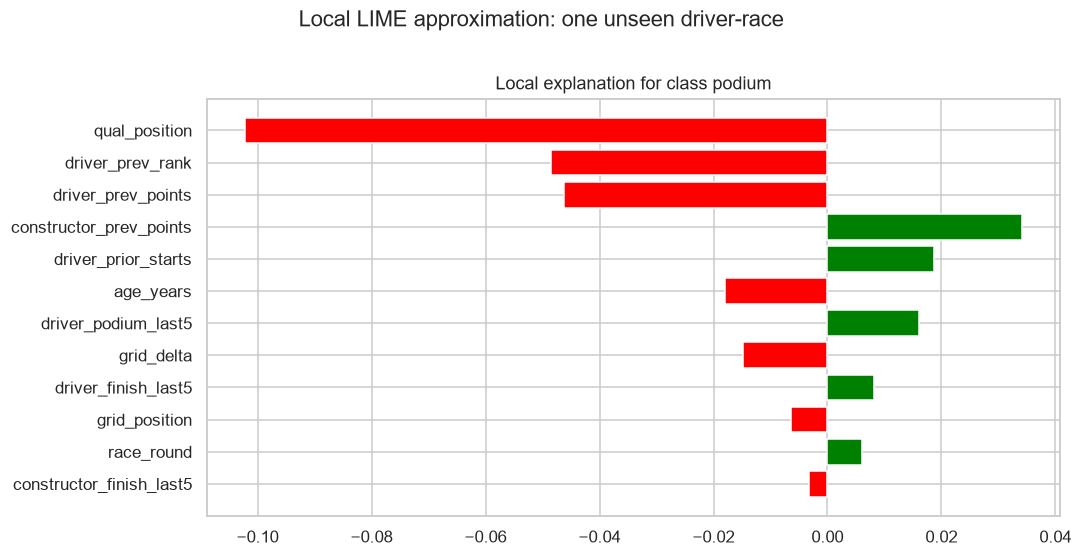

Global explanations disagree where predictors are correlated; neither measures causation.
Local case: race 1075 driver 1 actual label 0 predicted probability 0.085


**Explanation.** Permutation importance ranks **qual_position, driver_prev_rank, driver_prior_starts** highest by validation PR-AUC decrease. The SHAP summary highlights **qual_position, driver_prev_points, driver_prev_rankdriver_podium_last5 (+0.070)** on sampled validation rows. For the local prediction, SHAP's strongest upward terms are , driver_prior_starts (+0.067)** on sampled validation rows. For the local prediction, SHAP's strongest upward terms are , driver_prev_rank (+0.043); downward terms are qual_position (-0.166), age_years (-0.050), driver_standing_missing (-0.021). The LIME plot is a local surrogate for the same unseen input. Shared information among grid, qualifying, form and standings can divide importance across methods; none of these values establishes a causal effect.

In [27]:
from lime.lime_tabular import LimeTabularExplainer
lime_medians=X_train.median(numeric_only=True)
lime_train=X_train.fillna(lime_medians)
lime_example=pd.DataFrame([complete_record],columns=FEATURES).fillna(lime_medians)
lime_explainer=LimeTabularExplainer(lime_train.to_numpy(dtype=float),mode="classification",
    feature_names=FEATURES,class_names=["no podium","podium"],discretize_continuous=False,
    random_state=SEED)
def lime_predict(array):
    return selected_pipeline.predict_proba(pd.DataFrame(array,columns=FEATURES))
lime_explanation=lime_explainer.explain_instance(lime_example.iloc[0].to_numpy(dtype=float),
    lime_predict,labels=(1,),num_features=12,num_samples=1000)
fig=lime_explanation.as_pyplot_figure(label=1)
fig.suptitle("Local LIME approximation: one unseen driver-race",y=1.01)
save_plot("21_lime_local")
save_table("lime_local",pd.DataFrame(lime_explanation.as_list(label=1),columns=["feature","weight"]))
local_contributions=pd.DataFrame({"feature":FEATURES,"shap_value":local_values.values[0]})
save_table("shap_local",local_contributions.sort_values("shap_value",ascending=False))
local_up=[f"{r.feature} (+{r.shap_value:.3f})" for r in
          local_contributions.nlargest(3,"shap_value").itertuples() if r.shap_value>0]
local_down=[f"{r.feature} ({r.shap_value:.3f})" for r in
            local_contributions.nsmallest(3,"shap_value").itertuples() if r.shap_value<0]
SUMMARY["xai"].update({"top_permutation":perm_table.head(8).to_dict("records"),
    "top_shap":shap_magnitude.head(8).to_dict("records"),
    "local_shap_up":local_up,"local_shap_down":local_down,
    "local_race_id":int(test.loc[complete_index,"raceId"]),
    "local_driver_id":int(test.loc[complete_index,"driverId"]),
    "local_actual_podium":actual_test_label,
    "local_probability":float(selected_pipeline.predict_proba(lime_example)[:,1][0])})
print("Global explanations disagree where predictors are correlated; neither measures causation.")
print("Local case: race",SUMMARY["xai"]["local_race_id"],"driver",SUMMARY["xai"]["local_driver_id"],
      "actual label",actual_test_label,"predicted probability",round(SUMMARY["xai"]["local_probability"],3))
if "ipykernel" in sys.modules:
    display(Markdown("**Explanation.** Permutation importance ranks **"+
        ", ".join(perm_table.head(3).feature)+"** highest by validation PR-AUC decrease. "
        "The SHAP summary highlights **"+", ".join(shap_magnitude.head(3).feature)+
        "** on sampled validation rows. For the local prediction, SHAP's strongest upward terms are "
        ", ".join(local_up)+"; downward terms are "+", ".join(local_down)+
        ". The LIME plot is a local surrogate for the same unseen input. Shared information among "
        "grid, qualifying, form and standings can divide "
        "importance across methods; none of these values establishes a causal effect."))

## 13. Inference function and two demonstrations
Input is a dictionary of the **engineered pre-race fields** listed in
`FEATURES`. A caller may omit fields or supply `None`; the training-fitted
imputer fills them. Unexpected fields, including outcomes, are rejected.
For a new event, calculate form and standings only from races that ended
earlier than the target race; this notebook's historical table demonstrates
that construction. The same fixed model and validation-selected threshold
are used for both demonstrations.

In [28]:
def predict_podium(record:dict)->dict:
    if not isinstance(record,dict):
        raise TypeError("record must be a dictionary of pre-race feature values")
    extra=set(record)-set(FEATURES)
    if extra:
        raise ValueError(f"Unknown or forbidden fields: {sorted(extra)}")
    row={feature:(np.nan if record.get(feature) is None else record.get(feature,np.nan))
         for feature in FEATURES}
    frame=pd.DataFrame([row],columns=FEATURES)
    probability=float(selected_pipeline.predict_proba(frame)[0,1])
    return {"podium_probability":probability,
            "predicted_podium":int(probability>=winner["threshold"])}

complete_prediction=predict_podium(complete_record)
partial_record={k:v for k,v in complete_record.items() if k not in
    {"qual_position","grid_delta","driver_prev_points"}}
partial_prediction=predict_podium(partial_record)
assert 0<=complete_prediction["podium_probability"]<=1
assert 0<=partial_prediction["podium_probability"]<=1
try:
    predict_podium({"positionOrder":1})
    raise AssertionError("Post-race field must be rejected")
except ValueError:
    pass
print("Complete pre-race record:",complete_prediction)
print("Partially missing qualifying / standings record:",partial_prediction)
SUMMARY["modeling"]["inference"]={"complete":complete_prediction,"partial":partial_prediction,
    "complete_input_fields":len(complete_record),"partial_input_fields":len(partial_record)}

Complete pre-race record: {'podium_probability': 0.08516098122773148, 'predicted_podium': 0}
Partially missing qualifying / standings record: {'podium_probability': 0.17873606749916648, 'predicted_podium': 0}


## 14. Conclusion and limitations
The final model is chosen by validation PR-AUC and judged once on unseen
2022–2024 races. The notebook also reports F1, ROC-AUC, precision, and
recall, along with the baseline and every controlled attempt. Limitations:
qualifying records are unavailable before 1994 and patchy through 2002;
a 2003+ training population cannot claim to model early F1 faithfully;
2022 technical rules create distribution shift in the test era; constructor
renames reset constructorId histories; home-country comparison is
observational; and generic retirement codes make mechanical classification
uncertain. Actual starters form the evaluation population, so a late
pre-race withdrawal is outside this classifier's target population.
SHAP, LIME and permutation importance explain the fitted model only.

In [29]:
test_winner=comparison.loc[(comparison.model==winner_family)&(comparison.split=="test")].iloc[0]
print(f"Selected {winner_family}: validation PR-AUC {winner['val_pr_auc']:.3f}; "
      f"unseen test PR-AUC {test_winner.pr_auc:.3f}, ROC-AUC {test_winner.roc_auc:.3f}, "
      f"F1 {test_winner.f1:.3f}, precision {test_winner.precision:.3f}, recall {test_winner.recall:.3f}.")
print("Top validation ablation drops:\n",ablation.iloc[1:].nlargest(3,"delta_pr_auc")[
    ["removed","delta_pr_auc"]].to_string(index=False))
def json_safe(value):
    if isinstance(value,np.generic): return value.item()
    if isinstance(value,(pd.Timestamp,Path)): return str(value)
    if pd.isna(value): return None
    raise TypeError(f"Cannot serialize {type(value)}")
with (OUT/"summary.json").open("w",encoding="utf-8") as handle:
    json.dump(SUMMARY,handle,indent=2,default=json_safe,allow_nan=False)
print("Saved figures, tables and summary to",OUT.name)

Selected Logistic regression: validation PR-AUC 0.724; unseen test PR-AUC 0.709, ROC-AUC 0.936, F1 0.669, precision 0.579, recall 0.794.
Top validation ablation drops:
     removed  delta_pr_auc
Driver form      0.033444
 Qualifying      0.011040
  Standings      0.001477
Saved figures, tables and summary to outputs
